In [1]:
import pandas as pd
import numpy as np
import os

from datasets import load_dataset

In [2]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]
Python executable: C:\Users\PRAVEEN\AppData\Local\Programs\Python\Python312\python.exe


In [3]:
import numpy as np
import pandas as pd
import datasets

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Datasets:", datasets.__version__)

print("All libraries imported successfully!")

NumPy: 2.2.6
Pandas: 2.2.3
Datasets: 5.1.0
All libraries imported successfully!


In [4]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import os

In [5]:
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    split="train"
)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [6]:
df = dataset.to_pandas()

print("Dataset converted into DataFrame!")

Dataset converted into DataFrame!


In [7]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 26872
Total columns: 5


In [8]:
print("Column names:")

for col in df.columns:
    print(col)

Column names:
flags
instruction
category
intent
response


In [9]:
os.makedirs("data/raw", exist_ok=True)

df.to_csv(
    "data/raw/customer_support_raw.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [10]:
df = pd.read_csv("data/raw/customer_support_raw.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [11]:
df.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [12]:
df.tail()

,flags,instruction,category,intent,response
26867,BL,I am waiting for a rebate of {{Refund Amount}}...,REFUND,track_refund,Thank you for sharing your situation regarding...
26868,BIL,how to see if there is anything wrong with my ...,REFUND,track_refund,Ensuring the accuracy of your restitution is o...
26869,BLQZ,I'm waiting for a reimbjrsement of {{Currency ...,REFUND,track_refund,"Firstly, I genuinely understand the importance..."
26870,BL,I don't know what to do to see my reimbursemen...,REFUND,track_refund,I've understood you're unsure about how to che...
26871,BL,I need to know if there is anything new on the...,REFUND,track_refund,It's completely understandable that you want t...


In [13]:
print("Columns in dataset:")

for col in df.columns:
    print(col)

Columns in dataset:
flags
instruction
category
intent
response


In [14]:
X = df["instruction"]

In [15]:
y_category = df["category"]

In [16]:
y_intent = df["intent"]

In [17]:
print("Unique categories:")
print(df["category"].unique())

print("\nTotal categories:")
print(df["category"].nunique())

Unique categories:
['ORDER' 'SHIPPING' 'CANCEL' 'INVOICE' 'PAYMENT' 'REFUND' 'FEEDBACK'
 'CONTACT' 'ACCOUNT' 'DELIVERY' 'SUBSCRIPTION']

Total categories:
11


In [18]:
print("Unique intents:")
print(df["intent"].unique())

print("\nTotal intents:")
print(df["intent"].nunique())

Unique intents:
['cancel_order' 'change_order' 'change_shipping_address'
 'check_cancellation_fee' 'check_invoice' 'check_payment_methods'
 'check_refund_policy' 'complaint' 'contact_customer_service'
 'contact_human_agent' 'create_account' 'delete_account'
 'delivery_options' 'delivery_period' 'edit_account' 'get_invoice'
 'get_refund' 'newsletter_subscription' 'payment_issue' 'place_order'
 'recover_password' 'registration_problems' 'review'
 'set_up_shipping_address' 'switch_account' 'track_order' 'track_refund']

Total intents:
27


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


In [20]:
df.dtypes

flags          object
instruction    object
category       object
intent         object
response       object
dtype: object

In [21]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
print(df.info())

print("\nNumber of unique values:")
print(df.nunique())

Dataset shape: (26872, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB
None

Number of unique values:
flags            394
instruction    24635
category          11
intent            27
response       26870
dtype: int64


In [22]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [23]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [24]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


In [25]:
duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("Duplicate percentage:", duplicate_percentage)

Duplicate percentage: 0.0


In [26]:
duplicate_messages = df[
    df.duplicated(subset=["instruction"], keep=False)
]

print("Duplicate customer messages:",
      len(duplicate_messages))

duplicate_messages.head(10)

Duplicate customer messages: 3226


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
6,BCLN,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order,I pick up what you're putting down that you're...
7,BL,I am trying to cancel purchase {{Order Number}},ORDER,cancel_order,I've understood that you're seeking assistance...
8,BL,I have got to cancel purchase {{Order Number}},ORDER,cancel_order,I'm sensitive to the fact that you're seeking ...
9,BLQ,i need help canceling purchase {{Order Number}},ORDER,cancel_order,I perceive that you're seeking assistance with...
10,BQ,i dont know what to do to cancel order {{Order...,ORDER,cancel_order,I've taken note that you're unsure of the canc...
11,BL,I have a problem with cancelling purchase {{Or...,ORDER,cancel_order,I'm following you that you're facing difficult...
12,BL,problem with canceling purchase {{Order Number}},ORDER,cancel_order,I'm aware that you're facing difficulties canc...
13,BI,can you help me canceling order {{Order Number}}?,ORDER,cancel_order,I comprehend the urgency and complexity involv...


In [27]:
text_columns = ["instruction", "response"]

for col in text_columns:

    empty_count = (
        df[col]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )

    print(f"{col}: {empty_count} empty strings")

instruction: 0 empty strings
response: 0 empty strings


In [28]:
print("Unique category values:")

for value in df["category"].unique():
    print(repr(value))

Unique category values:
'ORDER'
'SHIPPING'
'CANCEL'
'INVOICE'
'PAYMENT'
'REFUND'
'FEEDBACK'
'CONTACT'
'ACCOUNT'
'DELIVERY'
'SUBSCRIPTION'


In [29]:
normalized_categories = (
    df["category"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Original unique categories:",
      df["category"].nunique())

print("Normalized unique categories:",
      normalized_categories.nunique())

Original unique categories: 11
Normalized unique categories: 11


In [30]:
normalized_intents = (
    df["intent"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Original unique intents:",
      df["intent"].nunique())

print("Normalized unique intents:",
      normalized_intents.nunique())

Original unique intents: 27
Normalized unique intents: 27


In [31]:
print("Category distribution:")

print(df["category"].value_counts(dropna=False))

Category distribution:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


In [32]:
print("Intent distribution:")

print(df["intent"].value_counts(dropna=False))

Intent distribution:
intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64


In [33]:
quality_report = pd.DataFrame({
    "Missing_Values": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ),
    "Unique_Values": df.nunique(dropna=False),
    "Data_Type": df.dtypes.astype(str)
})

print(quality_report)

             Missing_Values  Missing_Percentage  Unique_Values Data_Type
flags                     0                 0.0            394    object
instruction               0                 0.0          24635    object
category                  0                 0.0             11    object
intent                    0                 0.0             27    object
response                  0                 0.0          26870    object


In [34]:
print("All category labels:")

for category in sorted(df["category"].unique()):
    print(repr(category))

All category labels:
'ACCOUNT'
'CANCEL'
'CONTACT'
'DELIVERY'
'FEEDBACK'
'INVOICE'
'ORDER'
'PAYMENT'
'REFUND'
'SHIPPING'
'SUBSCRIPTION'


In [35]:
print(df["category"].value_counts())

category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


In [36]:
duplicate_analysis = (
    df[df.duplicated(subset=["instruction"], keep=False)]
    .groupby("instruction")
    .agg(
        total_records=("instruction", "size"),
        unique_categories=("category", "nunique"),
        unique_intents=("intent", "nunique"),
        unique_responses=("response", "nunique")
    )
    .reset_index()
)

duplicate_analysis.head(10)

,instruction,total_records,unique_categories,unique_intents,unique_responses
0,ETA of order {{Order Number}},5,1,1,5
1,ETA of purchase {{Order Number}},2,1,1,2
2,I am trying to cancel order {{Order Number}},2,1,1,2
3,I am trying to cancel purchaes {{Order Number}},2,1,1,2
4,I am trying to cancel purchase {{Order Number}},5,1,1,5
5,I am trying to change to the {{Account Categor...,2,1,1,2
6,I am trying to change to the {{Account Type}} ...,2,1,1,2
7,I am trying to download the bill from {{Person...,2,1,1,2
8,I am trying to find information about a {{Acco...,2,1,1,2
9,I am waiting for a compensation of {{Currency...,5,1,1,5


In [37]:
conflicting_messages = duplicate_analysis[
    (duplicate_analysis["unique_categories"] > 1) |
    (duplicate_analysis["unique_intents"] > 1)
]

print("Conflicting message groups:",
      len(conflicting_messages))

conflicting_messages.head(10)

Conflicting message groups: 0


,instruction,total_records,unique_categories,unique_intents,unique_responses


In [38]:
repeated_groups = duplicate_analysis.shape[0]

extra_duplicate_rows = df.duplicated(
    subset=["instruction"]
).sum()

print("Repeated message groups:", repeated_groups)
print("Extra repeated rows:", extra_duplicate_rows)
print("Rows belonging to repeated groups:", len(
    df[df.duplicated(subset=["instruction"], keep=False)]
))

Repeated message groups: 989
Extra repeated rows: 2237
Rows belonging to repeated groups: 3226


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [40]:
df = pd.read_csv("data/raw/customer_support_raw.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [41]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Total records:", len(df))


Total rows: 26872
Total columns: 5
Total records: 26872


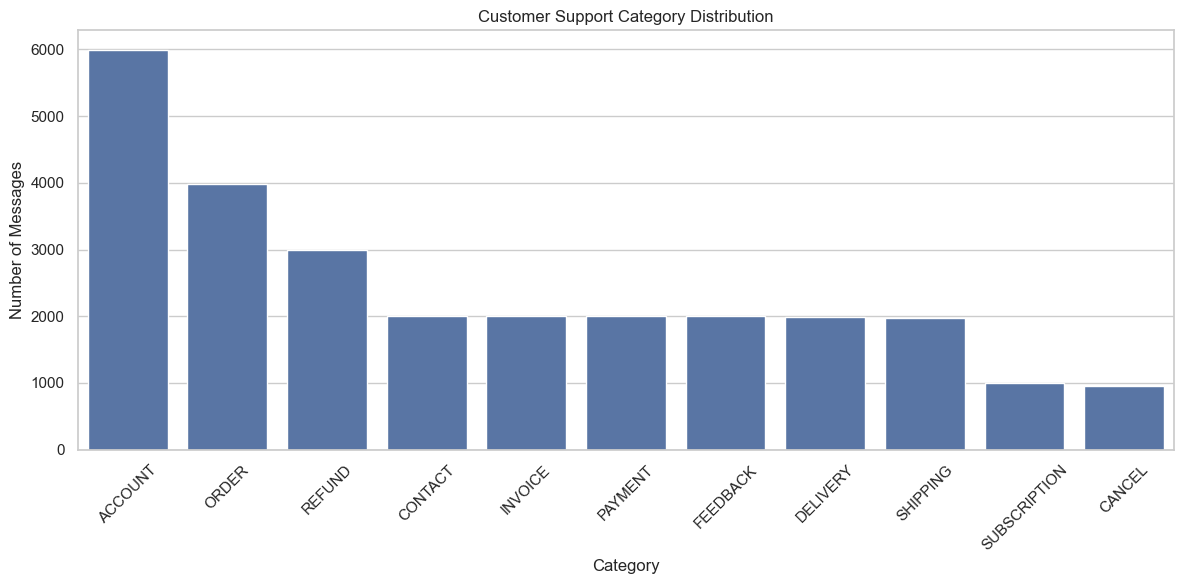

In [42]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Customer Support Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
intent_counts = df["intent"].value_counts()

print(intent_counts)

intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64


In [44]:
top_10_intents = df["intent"].value_counts().head(10)

print(top_10_intents)

intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
Name: count, dtype: int64


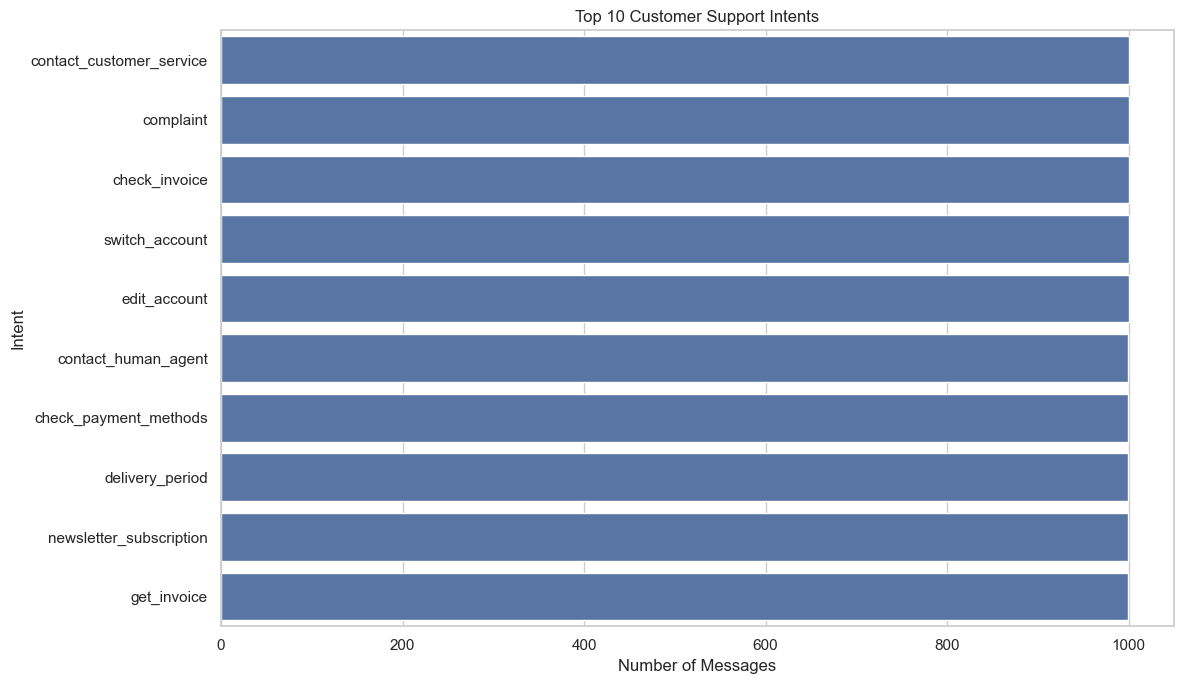

In [45]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_intents.values,
    y=top_10_intents.index
)

plt.title("Top 10 Customer Support Intents")
plt.xlabel("Number of Messages")
plt.ylabel("Intent")

plt.tight_layout()
plt.show()

In [46]:
class_counts = df["intent"].value_counts()

imbalance_ratio = (
    class_counts.max() / class_counts.min()
)

print("Maximum class count:", class_counts.max())
print("Minimum class count:", class_counts.min())

print("Imbalance ratio:", round(imbalance_ratio, 2))

Maximum class count: 1000
Minimum class count: 950
Imbalance ratio: 1.05


In [47]:
df["instruction_length"] = (
    df["instruction"].astype(str).str.len()
)

print(df["instruction_length"].describe())

count    26872.000000
mean        46.889513
std         10.897578
min          6.000000
25%         40.000000
50%         48.000000
75%         55.000000
max         92.000000
Name: instruction_length, dtype: float64


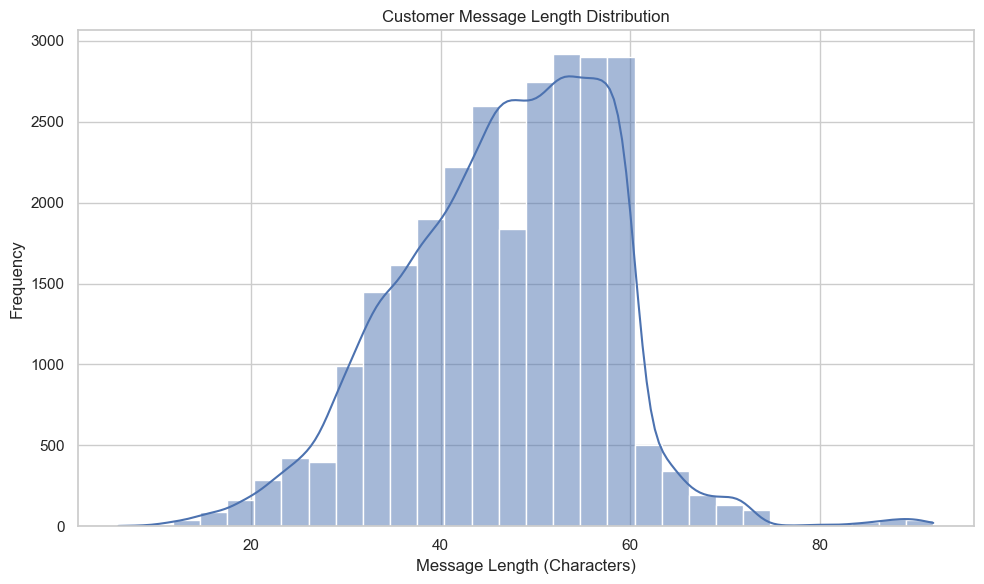

In [48]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="instruction_length",
    bins=30,
    kde=True
)

plt.title("Customer Message Length Distribution")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [49]:
df["word_count"] = (
    df["instruction"]
    .astype(str)
    .str.split()
    .str.len()
)

print(df["word_count"].describe())

count    26872.000000
mean         8.690979
std          2.605004
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         16.000000
Name: word_count, dtype: float64


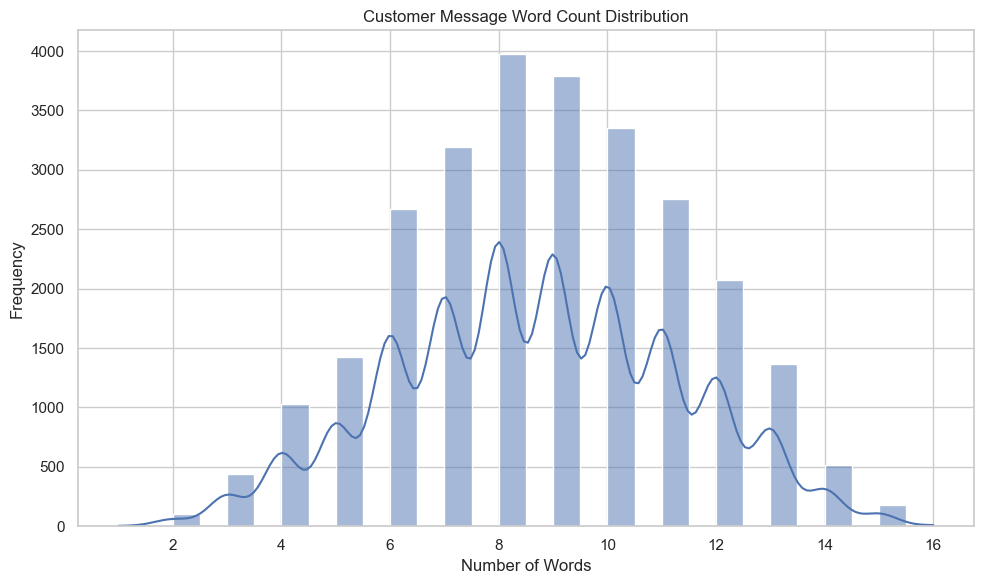

In [50]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    kde=True
)

plt.title("Customer Message Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [51]:
category_counts = df["category"].value_counts()

intent_counts = df["intent"].value_counts()

print("Category counts:")
print(category_counts)

print("\nIntent counts:")
print(intent_counts)

Category counts:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

Intent counts:
intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
d

In [52]:
import os

os.makedirs("reports", exist_ok=True)

category_counts.to_csv(
    "reports/category_distribution.csv"
)

intent_counts.to_csv(
    "reports/intent_distribution.csv"
)

print("EDA reports saved successfully!")

EDA reports saved successfully!


In [53]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [54]:
# Extract customer messages
text_data = df["instruction"].astype(str)

# Create a CountVectorizer
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

# Convert text into word counts
word_matrix = vectorizer.fit_transform(text_data)

# Calculate total frequency of each word
word_counts = word_matrix.sum(axis=0)

# Create a DataFrame
word_frequency = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts.A1
})

# Sort by frequency
word_frequency = word_frequency.sort_values(
    by="Frequency",
    ascending=False
)

print(word_frequency)

          Word  Frequency
6         help       6319
0      account       5400
11       order       4833
8         need       4059
19        want       3110
2   assistance       3005
10      number       2953
7         know       2691
3        check       2070
1      address       1949
12     payment       1609
14    purchase       1603
5     delivery       1486
4     customer       1229
15      refund       1159
16    shipping       1028
13      person       1020
17        type       1011
18          ur        946
9   newsletter        940


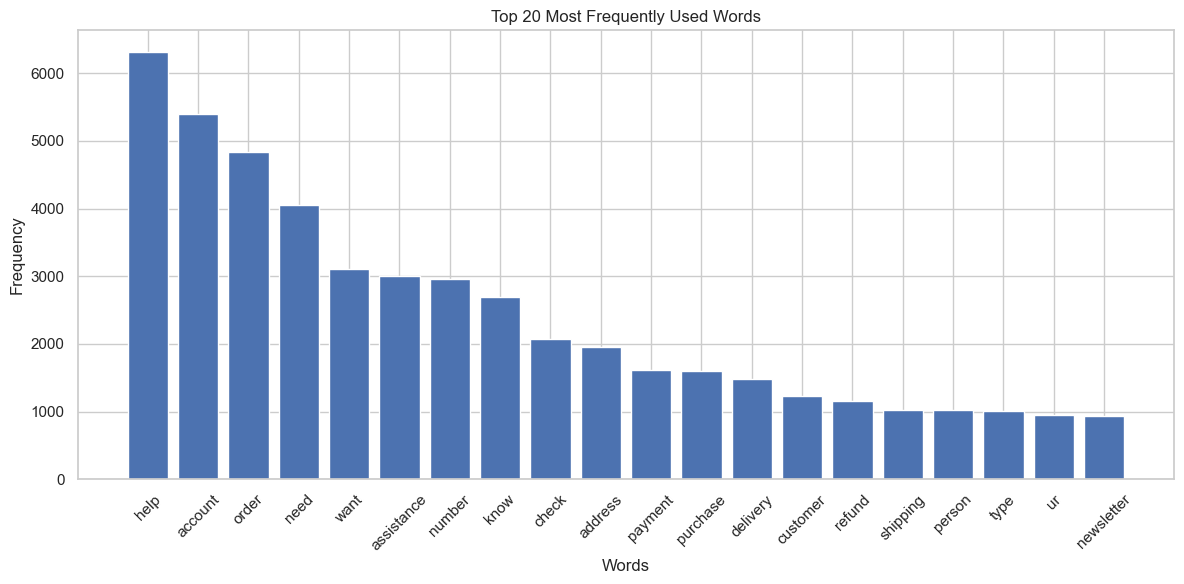

In [55]:
plt.figure(figsize=(12, 6))

plt.bar(
    word_frequency["Word"],
    word_frequency["Frequency"]
)

plt.title("Top 20 Most Frequently Used Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [56]:
from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20
)

bigram_matrix = bigram_vectorizer.fit_transform(
    df["instruction"].astype(str)
)

bigram_counts = bigram_matrix.sum(axis=0)

bigram_frequency = pd.DataFrame({
    "Bigram": bigram_vectorizer.get_feature_names_out(),
    "Frequency": bigram_counts.A1
})

bigram_frequency = bigram_frequency.sort_values(
    by="Frequency",
    ascending=False
)

print(bigram_frequency)

              Bigram  Frequency
11      order number       2907
12       order order       1454
10         need help       1355
13    purchase order       1351
19         want help       1201
9    need assistance       1089
1       account type       1011
18   want assistance        998
17      type account        869
6           don know        845
0   account category        822
14  shipping address        759
5   delivery address        725
2   category account        699
7          dont know        519
15  standard account        379
8         help check        376
3    currency symbol        372
16     symbol refund        372
4   customer support        366


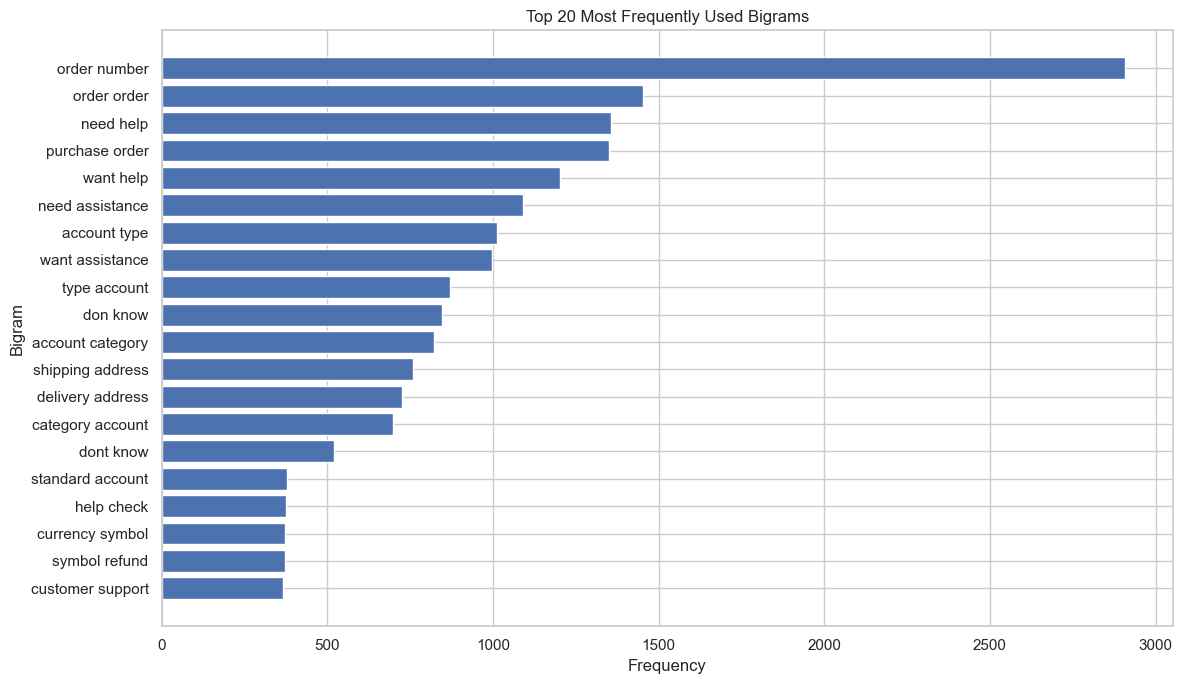

In [57]:
plt.figure(figsize=(12, 7))

plt.barh(
    bigram_frequency["Bigram"],
    bigram_frequency["Frequency"]
)

plt.title("Top 20 Most Frequently Used Bigrams")
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [58]:
from sklearn.feature_extraction.text import CountVectorizer

trigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(3, 3),
    max_features=20
)

trigram_matrix = trigram_vectorizer.fit_transform(
    df["instruction"].astype(str)
)

trigram_counts = trigram_matrix.sum(axis=0)

trigram_frequency = pd.DataFrame({
    "Trigram": trigram_vectorizer.get_feature_names_out(),
    "Frequency": trigram_counts.A1
})

trigram_frequency = trigram_frequency.sort_values(
    by="Frequency",
    ascending=False
)

print(trigram_frequency)

                       Trigram  Frequency
16          order order number       1454
17       purchase order number       1351
1         account type account        869
0     account category account        699
7       currency symbol refund        372
3        cancel purchase order        232
15         order number status        158
8              eta order order        155
2           cancel order order        144
9           eta purchase order        139
14        order number current        136
12       number current status        134
4     canceling purchase order        124
10        new delivery address        119
11        new shipping address        119
19  secondary shipping address        118
5    cancelling purchase order        116
6            check soon expect        113
18  secondary delivery address        110
13         order delivery city        102


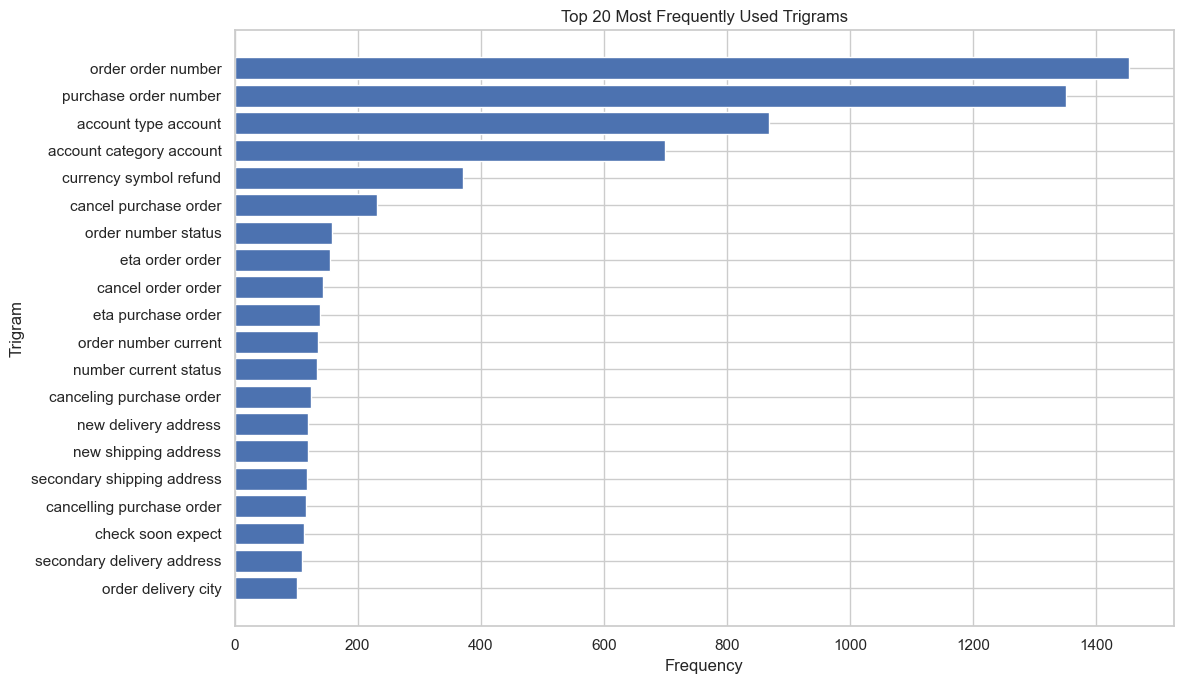

In [59]:
plt.figure(figsize=(12, 7))

plt.barh(
    trigram_frequency["Trigram"],
    trigram_frequency["Frequency"]
)

plt.title("Top 20 Most Frequently Used Trigrams")
plt.xlabel("Frequency")
plt.ylabel("Trigram")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [60]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Convert stopwords into a set
stop_words = set(ENGLISH_STOP_WORDS)

# Count stopword occurrences
def count_stopwords(text):
    words = str(text).lower().split()
    return sum(word in stop_words for word in words)

df["stopword_count"] = df["instruction"].apply(count_stopwords)

print("Stopword analysis:")
print(df["stopword_count"].describe())

print("\nTotal stopword occurrences:")
print(df["stopword_count"].sum())

print("\nAverage stopwords per message:")
print(round(df["stopword_count"].mean(), 2))

Stopword analysis:
count    26872.000000
mean         4.203669
std          2.381049
min          0.000000
25%          3.000000
50%          4.000000
75%          6.000000
max         13.000000
Name: stopword_count, dtype: float64

Total stopword occurrences:
112961

Average stopwords per message:
4.2


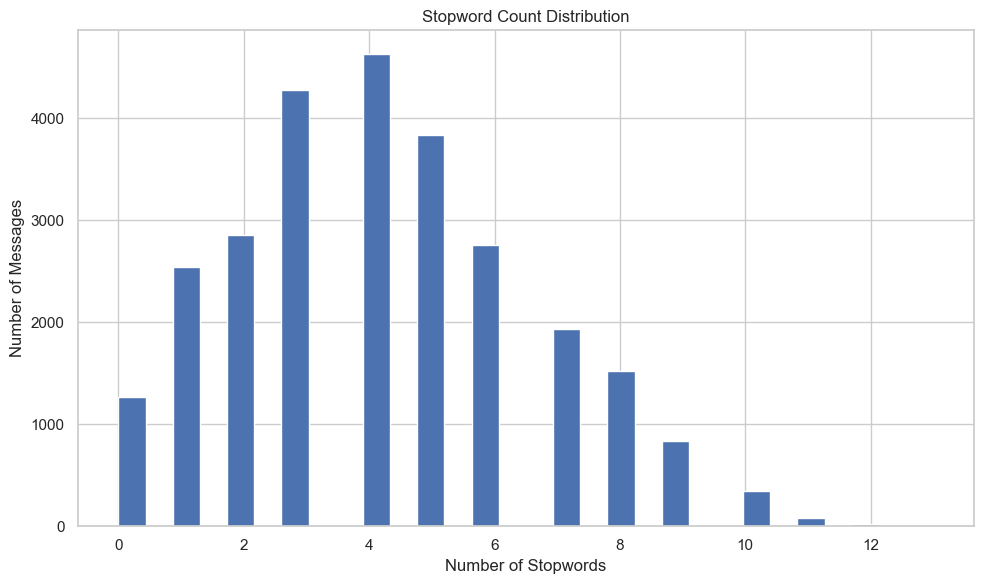

In [61]:
plt.figure(figsize=(10, 6))

plt.hist(df["stopword_count"], bins=30)

plt.title("Stopword Count Distribution")
plt.xlabel("Number of Stopwords")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.show()

In [62]:
# Calculate character length
df["instruction_length"] = df["instruction"].astype(str).str.len()

# Calculate word count
df["word_count"] = df["instruction"].astype(str).str.split().str.len()

# Group by category
category_text_analysis = df.groupby("category").agg(
    average_char_length=("instruction_length", "mean"),
    median_char_length=("instruction_length", "median"),
    average_word_count=("word_count", "mean"),
    total_messages=("instruction", "count")
).round(2)

print(category_text_analysis)

              average_char_length  median_char_length  average_word_count  \
category                                                                    
ACCOUNT                     45.42                45.0                8.28   
CANCEL                      43.97                44.0                8.17   
CONTACT                     44.03                45.0                8.82   
DELIVERY                    48.81                50.0                9.67   
FEEDBACK                    48.07                50.0                9.17   
INVOICE                     45.85                48.0                9.14   
ORDER                       46.81                48.0                8.18   
PAYMENT                     47.39                48.0                8.58   
REFUND                      50.72                52.0                9.48   
SHIPPING                    45.86                46.0                8.25   
SUBSCRIPTION                49.97                51.0                8.36   

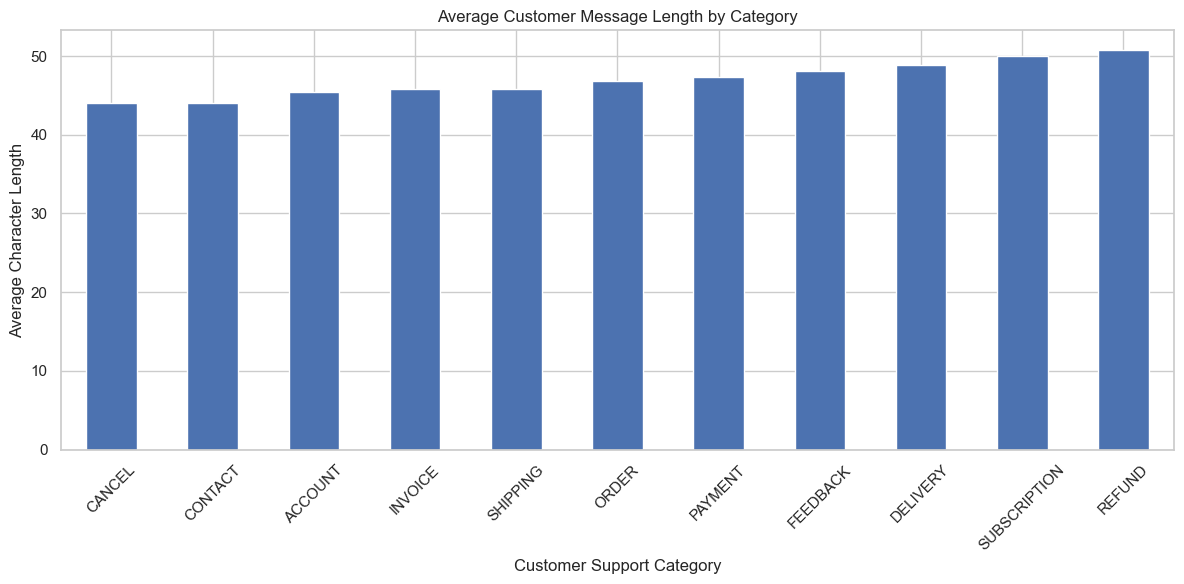

In [63]:
plt.figure(figsize=(12, 6))

category_text_analysis["average_char_length"].sort_values().plot(
    kind="bar"
)

plt.title("Average Customer Message Length by Category")
plt.xlabel("Customer Support Category")
plt.ylabel("Average Character Length")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

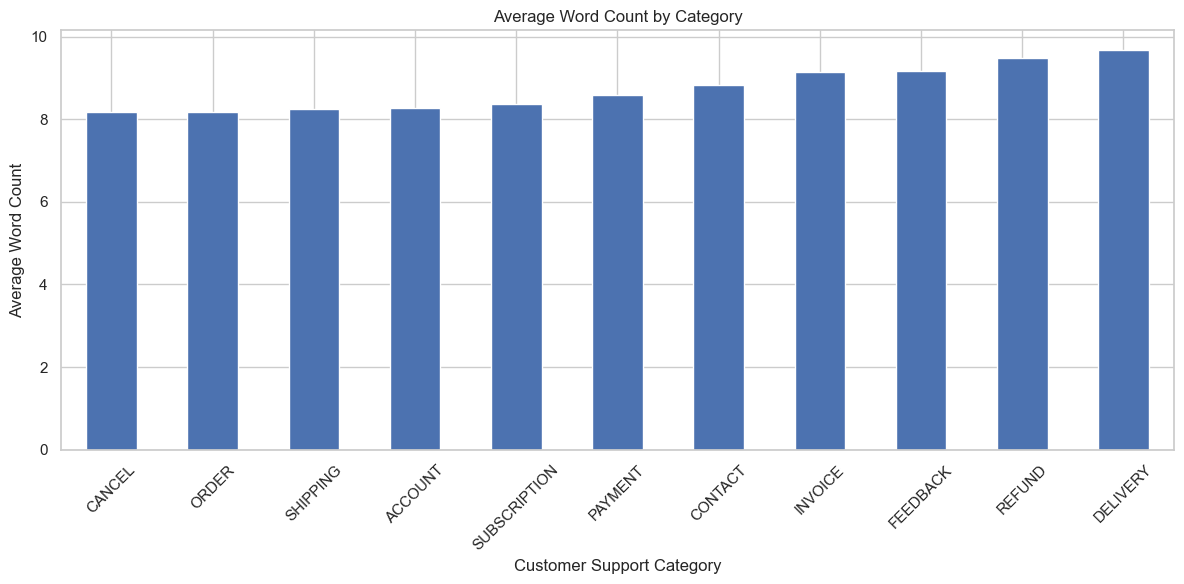

In [64]:
plt.figure(figsize=(12, 6))

category_text_analysis["average_word_count"].sort_values().plot(
    kind="bar"
)

plt.title("Average Word Count by Category")
plt.xlabel("Customer Support Category")
plt.ylabel("Average Word Count")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [65]:
import re

# Count numbers in each message
df["number_count"] = df["instruction"].apply(
    lambda text: len(re.findall(r"\d+", str(text)))
)

# Count special characters
df["special_char_count"] = df["instruction"].apply(
    lambda text: len(re.findall(r"[^a-zA-Z0-9\s]", str(text)))
)

# Count URLs
df["url_count"] = df["instruction"].apply(
    lambda text: len(
        re.findall(r"https?://\S+|www\.\S+", str(text), flags=re.IGNORECASE)
    )
)

# Count email addresses
df["email_count"] = df["instruction"].apply(
    lambda text: len(
        re.findall(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            str(text)
        )
    )
)

print("Number of messages containing numbers:",
      (df["number_count"] > 0).sum())

print("Number of messages containing special characters:",
      (df["special_char_count"] > 0).sum())

print("Number of messages containing URLs:",
      (df["url_count"] > 0).sum())

print("Number of messages containing email addresses:",
      (df["email_count"] > 0).sum())

Number of messages containing numbers: 1089
Number of messages containing special characters: 13546
Number of messages containing URLs: 0
Number of messages containing email addresses: 0


In [66]:
pattern_summary = df[
    [
        "number_count",
        "special_char_count",
        "url_count",
        "email_count"
    ]
].describe()

print(pattern_summary)

       number_count  special_char_count  url_count  email_count
count  26872.000000        26872.000000    26872.0      26872.0
mean       0.040525            1.417274        0.0          0.0
std        0.197192            1.917487        0.0          0.0
min        0.000000            0.000000        0.0          0.0
25%        0.000000            0.000000        0.0          0.0
50%        0.000000            1.000000        0.0          0.0
75%        0.000000            3.000000        0.0          0.0
max        1.000000           10.000000        0.0          0.0


In [67]:
text_analysis_summary = pd.DataFrame({
    "Metric": [
        "Total Messages",
        "Average Character Length",
        "Median Character Length",
        "Average Word Count",
        "Average Stopword Count",
        "Messages Containing Numbers",
        "Messages Containing Special Characters",
        "Messages Containing URLs",
        "Messages Containing Email Addresses"
    ],
    "Value": [
        len(df),
        round(df["instruction_length"].mean(), 2),
        round(df["instruction_length"].median(), 2),
        round(df["word_count"].mean(), 2),
        round(df["stopword_count"].mean(), 2),
        (df["number_count"] > 0).sum(),
        (df["special_char_count"] > 0).sum(),
        (df["url_count"] > 0).sum(),
        (df["email_count"] > 0).sum()
    ]
})

print(text_analysis_summary)

                                   Metric     Value
0                          Total Messages  26872.00
1                Average Character Length     46.89
2                 Median Character Length     48.00
3                      Average Word Count      8.69
4                  Average Stopword Count      4.20
5             Messages Containing Numbers   1089.00
6  Messages Containing Special Characters  13546.00
7                Messages Containing URLs      0.00
8     Messages Containing Email Addresses      0.00


In [68]:
import os

os.makedirs("reports", exist_ok=True)

text_analysis_summary.to_csv(
    "reports/text_analysis_summary.csv",
    index=False
)

print("Text analysis report saved successfully!")

Text analysis report saved successfully!


In [69]:
import pandas as pd
import numpy as np
import os

# Load original raw dataset
df_raw = pd.read_csv(
    "data/raw/customer_support_raw.csv"
)

# Create a working copy
df_prepared = df_raw.copy()

print("Raw dataset shape:", df_raw.shape)
print("Working dataset shape:", df_prepared.shape)

print("\nWorking dataset columns:")
print(df_prepared.columns.tolist())

print("\nFirst 5 records:")
display(df_prepared.head())

Raw dataset shape: (26872, 5)
Working dataset shape: (26872, 5)

Working dataset columns:
['flags', 'instruction', 'category', 'intent', 'response']

First 5 records:


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [70]:
# Select relevant columns
selected_columns = [
    "instruction",
    "category",
    "intent",
    "response"
]

df_prepared = df_prepared[selected_columns].copy()

print("Selected dataset shape:", df_prepared.shape)

print("\nSelected columns:")
print(df_prepared.columns.tolist())

print("\nFirst 5 records:")
display(df_prepared.head())

Selected dataset shape: (26872, 4)

Selected columns:
['instruction', 'category', 'intent', 'response']

First 5 records:


,instruction,category,intent,response
0,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [71]:
print("Original raw dataset:", df_raw.shape)
print("Prepared dataset:", df_prepared.shape)

print("\nDifference in rows:",
      len(df_prepared) - len(df_raw))


Original raw dataset: (26872, 5)
Prepared dataset: (26872, 4)

Difference in rows: 0


In [72]:
print("Raw dataset rows:", len(df_raw))
print("Prepared dataset rows:", len(df_prepared))

print("\nAre row counts equal?",
      len(df_raw) == len(df_prepared))

Raw dataset rows: 26872
Prepared dataset rows: 26872

Are row counts equal? True


In [73]:
# Count repeated customer messages
duplicate_message_count = df_prepared.duplicated(
    subset=["instruction"]
).sum()

print("Repeated message rows:", duplicate_message_count)

# Count all rows belonging to repeated-message groups
repeated_message_rows = df_prepared[
    df_prepared.duplicated(
        subset=["instruction"],
        keep=False
    )
]

print(
    "Total rows belonging to repeated-message groups:",
    len(repeated_message_rows)
)

Repeated message rows: 2237
Total rows belonging to repeated-message groups: 3226


In [74]:
duplicate_analysis = (
    df_prepared.groupby("instruction")
    .agg(
        total_records=("instruction", "size"),
        unique_categories=("category", "nunique"),
        unique_intents=("intent", "nunique"),
        unique_responses=("response", "nunique")
    )
    .reset_index()
)

conflicting_messages = duplicate_analysis[
    (duplicate_analysis["unique_categories"] > 1) |
    (duplicate_analysis["unique_intents"] > 1)
]

print(
    "Number of conflicting message groups:",
    len(conflicting_messages)
)

display(conflicting_messages.head(10))

Number of conflicting message groups: 0


,instruction,total_records,unique_categories,unique_intents,unique_responses


In [75]:
# Find repeated messages that have different responses
response_variations = duplicate_analysis[
    (duplicate_analysis["total_records"] > 1) &
    (duplicate_analysis["unique_responses"] > 1)
]

print(
    "Repeated message groups with different responses:",
    len(response_variations)
)

print("\nExamples:")
display(response_variations.head(10))


Repeated message groups with different responses: 989

Examples:


,instruction,total_records,unique_categories,unique_intents,unique_responses
1,ETA of order {{Order Number}},5,1,1,5
3,ETA of purchase {{Order Number}},2,1,1,2
173,I am trying to cancel order {{Order Number}},2,1,1,2
174,I am trying to cancel purchaes {{Order Number}},2,1,1,2
175,I am trying to cancel purchase {{Order Number}},5,1,1,5
179,I am trying to change to the {{Account Categor...,2,1,1,2
180,I am trying to change to the {{Account Type}} ...,2,1,1,2
220,I am trying to download the bill from {{Person...,2,1,1,2
232,I am trying to find information about a {{Acco...,2,1,1,2
422,I am waiting for a compensation of {{Currency...,5,1,1,5


In [76]:
# Normalize category labels
df_prepared["category"] = (
    df_prepared["category"]
    .astype(str)
    .str.strip()
)

# Normalize intent labels
df_prepared["intent"] = (
    df_prepared["intent"]
    .astype(str)
    .str.strip()
)

print("Category normalization completed!")
print("Intent normalization completed!")

Category normalization completed!
Intent normalization completed!


In [77]:
print("Unique categories:", df_prepared["category"].nunique())
print("Unique intents:", df_prepared["intent"].nunique())

print("\nCategory labels:")
print(sorted(df_prepared["category"].unique()))

print("\nIntent labels:")
print(sorted(df_prepared["intent"].unique()))

Unique categories: 11
Unique intents: 27

Category labels:
['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']

Intent labels:
['cancel_order', 'change_order', 'change_shipping_address', 'check_cancellation_fee', 'check_invoice', 'check_payment_methods', 'check_refund_policy', 'complaint', 'contact_customer_service', 'contact_human_agent', 'create_account', 'delete_account', 'delivery_options', 'delivery_period', 'edit_account', 'get_invoice', 'get_refund', 'newsletter_subscription', 'payment_issue', 'place_order', 'recover_password', 'registration_problems', 'review', 'set_up_shipping_address', 'switch_account', 'track_order', 'track_refund']


In [78]:
print("Missing values in each column:")
print(df_prepared.isnull().sum())

print("\nTotal missing values:")
print(df_prepared.isnull().sum().sum())

Missing values in each column:
instruction    0
category       0
intent         0
response       0
dtype: int64

Total missing values:
0


In [79]:
print("Empty customer messages:",
      (df_prepared["instruction"].str.strip() == "").sum())

print("Empty category labels:",
      (df_prepared["category"].str.strip() == "").sum())

print("Empty intent labels:",
      (df_prepared["intent"].str.strip() == "").sum())

print("Empty responses:",
      (df_prepared["response"].str.strip() == "").sum())

Empty customer messages: 0
Empty category labels: 0
Empty intent labels: 0
Empty responses: 0


In [80]:
print(df_prepared.dtypes)

print("\nDataset information:")
df_prepared.info()

instruction    object
category       object
intent         object
response       object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   instruction  26872 non-null  object
 1   category     26872 non-null  object
 2   intent       26872 non-null  object
 3   response     26872 non-null  object
dtypes: object(4)
memory usage: 839.9+ KB


In [81]:
print("Dataset shape:", df_prepared.shape)

print("Unique categories:",
      df_prepared["category"].nunique())

print("Unique intents:",
      df_prepared["intent"].nunique())

print("Exact duplicate rows:",
      df_prepared.duplicated().sum())

Dataset shape: (26872, 4)
Unique categories: 11
Unique intents: 27
Exact duplicate rows: 0


In [82]:
import os

# Create processed data directory
os.makedirs("data/processed", exist_ok=True)

# Save prepared dataset
df_prepared.to_csv(
    "data/processed/customer_support_prepared.csv",
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [83]:
# Load the saved dataset
df_check = pd.read_csv(
    "data/processed/customer_support_prepared.csv"
)

print("Saved dataset shape:", df_check.shape)

print("\nSaved dataset columns:")
print(df_check.columns.tolist())

print("\nFirst 5 records:")
display(df_check.head())

Saved dataset shape: (26872, 4)

Saved dataset columns:
['instruction', 'category', 'intent', 'response']

First 5 records:


,instruction,category,intent,response
0,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [84]:
print("Original prepared shape:", df_prepared.shape)
print("Reloaded dataset shape:", df_check.shape)

print("\nAre both datasets identical?",
      df_prepared.equals(df_check))

Original prepared shape: (26872, 4)
Reloaded dataset shape: (26872, 4)

Are both datasets identical? True


In [85]:
# Input feature: customer message
X = df_prepared["instruction"]

# Target 1: category classification
y_category = df_prepared["category"]

# Target 2: intent classification
y_intent = df_prepared["intent"]

print("Input feature shape:", X.shape)
print("Category target shape:", y_category.shape)
print("Intent target shape:", y_intent.shape)

Input feature shape: (26872,)
Category target shape: (26872,)
Intent target shape: (26872,)


In [86]:
print("Sample input messages:")
display(X.head())

print("\nSample category labels:")
display(y_category.head())

print("\nSample intent labels:")
display(y_intent.head())

Sample input messages:


0     question about cancelling order {{Order Number}}
1    i have a question about cancelling oorder {{Or...
2      i need help cancelling puchase {{Order Number}}
3           I need to cancel purchase {{Order Number}}
4    I cannot afford this order, cancel purchase {{...
Name: instruction, dtype: object


Sample category labels:


0    ORDER
1    ORDER
2    ORDER
3    ORDER
4    ORDER
Name: category, dtype: object


Sample intent labels:


0    cancel_order
1    cancel_order
2    cancel_order
3    cancel_order
4    cancel_order
Name: intent, dtype: object

In [87]:
# Create a combined ML-ready dataset
df_ml_ready = pd.DataFrame({
    "instruction": X,
    "category": y_category,
    "intent": y_intent
})

print("ML-ready dataset shape:", df_ml_ready.shape)

display(df_ml_ready.head())

ML-ready dataset shape: (26872, 3)


,instruction,category,intent
0,question about cancelling order {{Order Number}},ORDER,cancel_order
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order


In [88]:
import os

os.makedirs("data/processed", exist_ok=True)

df_ml_ready.to_csv(
    "data/processed/customer_support_ml_ready.csv",
    index=False
)

print("ML-ready dataset saved successfully!")

ML-ready dataset saved successfully!


In [89]:
df_ml_check = pd.read_csv(
    "data/processed/customer_support_ml_ready.csv"
)

print("Saved dataset shape:", df_ml_check.shape)

print("\nColumns:", df_ml_check.columns.tolist())

print("\nMissing values:")
print(df_ml_check.isnull().sum())

print("\nExact duplicate rows:",
      df_ml_check.duplicated().sum())

Saved dataset shape: (26872, 3)

Columns: ['instruction', 'category', 'intent']

Missing values:
instruction    0
category       0
intent         0
dtype: int64

Exact duplicate rows: 2237


In [90]:
dataset_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Features",
        "Unique Categories",
        "Unique Intents",
        "Missing Values",
        "Duplicate Rows",
        "Average Message Length",
        "Average Word Count"
    ],
    "Value": [
        len(df_ml_ready),
        df_ml_ready.shape[1],
        df_ml_ready["category"].nunique(),
        df_ml_ready["intent"].nunique(),
        df_ml_ready.isnull().sum().sum(),
        df_ml_ready.duplicated().sum(),
        round(df_ml_ready["instruction"].str.len().mean(), 2),
        round(df_ml_ready["instruction"].str.split().str.len().mean(), 2)
    ]
})

display(dataset_summary)

,Metric,Value
0,Total Records,26872.00
1,Total Features,3.00
2,Unique Categories,11.00
3,Unique Intents,27.00
4,Missing Values,0.00
5,Duplicate Rows,2237.00
6,Average Message Length,46.89
7,Average Word Count,8.69


In [91]:
dataset_summary.to_csv(
    "reports/dataset_preparation_summary.csv",
    index=False
)

print("Dataset preparation summary saved successfully!")

Dataset preparation summary saved successfully!


In [92]:
# Check ML-ready dataset columns
print("ML-ready dataset columns:")
print(df_ml_ready.columns.tolist())

# Check input features
print("\nInput feature columns:")
X = df_ml_ready[["instruction"]]

# Check target variables
y_category = df_ml_ready["category"]
y_intent = df_ml_ready["intent"]

print("\nCategory target:", y_category.name)
print("Intent target:", y_intent.name)

# Verify target columns are not inside X
print("\nIs category inside X?",
      "category" in X.columns)

print("Is intent inside X?",
      "intent" in X.columns)

ML-ready dataset columns:
['instruction', 'category', 'intent']

Input feature columns:

Category target: category
Intent target: intent

Is category inside X? False
Is intent inside X? False


In [93]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Incorrect: fitting on the entire dataset
tfidf = TfidfVectorizer()

X_tfidf = tfidf.fit_transform(
    df_ml_ready["instruction"]
)

# Splitting after vectorization

In [94]:
from sklearn.model_selection import GroupShuffleSplit

print("GroupShuffleSplit imported successfully!")

GroupShuffleSplit imported successfully!


In [95]:
# Input feature
X = df_ml_ready["instruction"]

# Target variables
y_category = df_ml_ready["category"]
y_intent = df_ml_ready["intent"]

# Group identifier: identical messages belong to the same group
groups = df_ml_ready["instruction"]

print("Input shape:", X.shape)
print("Category target shape:", y_category.shape)
print("Intent target shape:", y_intent.shape)
print("Unique message groups:", groups.nunique())

Input shape: (26872,)
Category target shape: (26872,)
Intent target shape: (26872,)
Unique message groups: 24635


In [96]:
# Initialize group-aware splitter
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Generate training and testing indices
train_idx, test_idx = next(
    gss.split(X, y_category, groups=groups)
)

# Split input features
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Split category targets
y_category_train = y_category.iloc[train_idx]
y_category_test = y_category.iloc[test_idx]

# Split intent targets
y_intent_train = y_intent.iloc[train_idx]
y_intent_test = y_intent.iloc[test_idx]

print("Train-test split completed!")

Train-test split completed!


In [97]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2))

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2))

# Verify no identical messages exist in both sets
train_groups = set(X_train)
test_groups = set(X_test)

overlap = train_groups.intersection(test_groups)

print("\nIdentical messages in both sets:", len(overlap))

Training records: 21466
Testing records: 5406

Training percentage: 79.88
Testing percentage: 20.12

Identical messages in both sets: 0


In [98]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

print("TF-IDF vectorizer initialized successfully!")

TF-IDF vectorizer initialized successfully!


In [99]:
# Learn vocabulary and transform training messages
X_train_tfidf = tfidf.fit_transform(X_train)

print("Training TF-IDF shape:", X_train_tfidf.shape)

Training TF-IDF shape: (21466, 5000)


In [100]:
# Use the training vocabulary to transform test messages
X_test_tfidf = tfidf.transform(X_test)

print("Testing TF-IDF shape:", X_test_tfidf.shape)

Testing TF-IDF shape: (5406, 5000)


In [101]:
#Verify the vocabulary
print("Vocabulary size:", len(tfidf.vocabulary_))

print("\nFirst 20 vocabulary words:")
print(list(tfidf.vocabulary_.keys())[:20])

print("\nTraining matrix type:", type(X_train_tfidf))
print("Testing matrix type:", type(X_test_tfidf))

Vocabulary size: 5000

First 20 vocabulary words:
['question', 'cancelling', 'order', 'number', 'question cancelling', 'cancelling order', 'order order', 'order number', 'oorder', 'oorder order', 'need', 'help', 'puchase', 'need help', 'help cancelling', 'cancelling puchase', 'puchase order', 'cancel', 'purchase', 'need cancel']

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Testing matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [102]:
#Verify training and testing dimensions
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF:", X_test_tfidf.shape)

print("\nCategory training target:", y_category_train.shape)
print("Category testing target:", y_category_test.shape)

print("\nIntent training target:", y_intent_train.shape)
print("Intent testing target:", y_intent_test.shape)

X_train TF-IDF: (21466, 5000)
X_test TF-IDF: (5406, 5000)

Category training target: (21466,)
Category testing target: (5406,)

Intent training target: (21466,)
Intent testing target: (5406,)


In [103]:
#Verify no duplicate messages cross the split
train_messages = set(X_train)
test_messages = set(X_test)

common_messages = train_messages.intersection(test_messages)

print("Common messages:", len(common_messages))

Common messages: 0


In [104]:
#Verify target labels
print("Training categories:",
      y_category_train.nunique())

print("Testing categories:",
      y_category_test.nunique())

print("\nTraining intents:",
      y_intent_train.nunique())

print("Testing intents:",
      y_intent_test.nunique())

Training categories: 11
Testing categories: 11

Training intents: 27
Testing intents: 27


In [105]:
#Verify vectorizer fitting
print("Vocabulary learned from training data:",
      len(tfidf.vocabulary_))

print("Training matrix columns:",
      X_train_tfidf.shape[1])

print("Testing matrix columns:",
      X_test_tfidf.shape[1])

print("Same feature dimensions:",
      X_train_tfidf.shape[1] == X_test_tfidf.shape[1])

Vocabulary learned from training data: 5000
Training matrix columns: 5000
Testing matrix columns: 5000
Same feature dimensions: True


In [106]:
#Create a preprocessing working copy
df_nlp = pd.read_csv(
    "data/processed/customer_support_prepared.csv"
)

# Preserve the original message
df_nlp["instruction_raw"] = df_nlp["instruction"]

print("Dataset shape:", df_nlp.shape)
print("\nColumns:", df_nlp.columns.tolist())

display(df_nlp[["instruction_raw"]].head())

Dataset shape: (26872, 5)

Columns: ['instruction', 'category', 'intent', 'response', 'instruction_raw']


,instruction_raw
0,question about cancelling order {{Order Number}}
1,i have a question about cancelling oorder {{Or...
2,i need help cancelling puchase {{Order Number}}
3,I need to cancel purchase {{Order Number}}
4,"I cannot afford this order, cancel purchase {{..."


In [107]:
# Show a few raw customer messages
for i, text in enumerate(df_nlp["instruction_raw"].head(10), start=1):
    print(f"{i}. {text}")
    print("-" * 80)

1. question about cancelling order {{Order Number}}
--------------------------------------------------------------------------------
2. i have a question about cancelling oorder {{Order Number}}
--------------------------------------------------------------------------------
3. i need help cancelling puchase {{Order Number}}
--------------------------------------------------------------------------------
4. I need to cancel purchase {{Order Number}}
--------------------------------------------------------------------------------
5. I cannot afford this order, cancel purchase {{Order Number}}
--------------------------------------------------------------------------------
6. can you help me cancel order {{Order Number}}?
--------------------------------------------------------------------------------
7. I can no longer afford order {{Order Number}}, cancel it
--------------------------------------------------------------------------------
8. I am trying to cancel purchase {{Order Number

In [108]:
#Measure text patterns
import re

text = df_nlp["instruction_raw"].fillna("")

print("Missing messages:", df_nlp["instruction_raw"].isna().sum())
print("Blank messages:", text.str.strip().eq("").sum())
print("Messages with leading/trailing spaces:",
      text.ne(text.str.strip()).sum())
print("Messages containing a placeholder:",
      text.str.contains(r"\{\{.*?\}\}", regex=True).sum())

# Show distinct placeholders found in the messages
placeholders = sorted(set(
    re.findall(r"\{\{.*?\}\}", " ".join(text.astype(str)))
))
print("Distinct placeholders:", placeholders)

Missing messages: 0
Blank messages: 0
Messages with leading/trailing spaces: 0
Messages containing a placeholder: 6670
Distinct placeholders: ['{{Account Category}}', '{{Account Type}}', '{{Currency Symbol}}', '{{Delivery City}}', '{{Delivery Country}}', '{{Invoice Number}}', '{{Order Number}}', '{{Person Name}}', '{{Refund Amount}}']


In [109]:
#Check for URLs, emails, and numbers


texts = df_nlp["instruction_raw"].astype(str)

url_count = texts.str.contains(r"https?://|www\.", case=False, regex=True).sum()
email_count = texts.str.contains(
    r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", regex=True
).sum()
number_count = texts.str.contains(r"\d", regex=True).sum()

print("Messages containing URLs:", url_count)
print("Messages containing email addresses:", email_count)
print("Messages containing digits:", number_count)

Messages containing URLs: 0
Messages containing email addresses: 0
Messages containing digits: 1089


In [110]:
#Inspect examples containing digits
digit_examples = df_nlp.loc[
    df_nlp["instruction_raw"].str.contains(r"\d", regex=True),
    "instruction_raw"
].head(10)

for i, text in enumerate(digit_examples, start=1):
    print(f"{i}. {text}")
    print("-" * 80)

1. cancel purchase732201349959
--------------------------------------------------------------------------------
2. I need help to cancel purchase370795561790
--------------------------------------------------------------------------------
3. cancel purchase370795561790
--------------------------------------------------------------------------------
4. cancel purchase00123842
--------------------------------------------------------------------------------
5. cancel purchase113542617735902
--------------------------------------------------------------------------------
6. cancel purchase00004587345
--------------------------------------------------------------------------------
7. i cant add some items to order370795561790
--------------------------------------------------------------------------------
8. update purchase00004587345
--------------------------------------------------------------------------------
9. need to change several products of purchase113542617735902
---------------

In [111]:
#Create a cleaned-text column
df_nlp["instruction_clean"] = (
    df_nlp["instruction_raw"]
    .str.lower()
    .str.strip()
)

display(df_nlp[["instruction_raw", "instruction_clean"]].head(10))

,instruction_raw,instruction_clean
0,question about cancelling order {{Order Number}},question about cancelling order {{order number}}
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling oorder {{or...
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase {{order number}}
3,I need to cancel purchase {{Order Number}},i need to cancel purchase {{order number}}
4,"I cannot afford this order, cancel purchase {{...","i cannot afford this order, cancel purchase {{..."
5,can you help me cancel order {{Order Number}}?,can you help me cancel order {{order number}}?
6,"I can no longer afford order {{Order Number}},...","i can no longer afford order {{order number}},..."
7,I am trying to cancel purchase {{Order Number}},i am trying to cancel purchase {{order number}}
8,I have got to cancel purchase {{Order Number}},i have got to cancel purchase {{order number}}
9,i need help canceling purchase {{Order Number}},i need help canceling purchase {{order number}}


In [112]:
#Check what changed
print("Rows:", len(df_nlp))
print("Blank cleaned messages:", df_nlp["instruction_clean"].str.strip().eq("").sum())
print(
    "Rows changed by lowercase/trim:",
    df_nlp["instruction_raw"].ne(df_nlp["instruction_clean"]).sum()
)

Rows: 26872
Blank cleaned messages: 0
Rows changed by lowercase/trim: 15679


In [113]:
#Save the cleaned text
df_nlp.to_csv(
    "data/processed/customer_support_nlp_step2.csv",
    index=False
)

print("Saved:", "data/processed/customer_support_nlp_step2.csv")

Saved: data/processed/customer_support_nlp_step2.csv


In [114]:
#Check spelling variants
terms_to_check = [
    "cancelling",
    "canceling",
    "puchase",
    "oorder",
    "purchase",
    "order",
]

for term in terms_to_check:
    count = df_nlp["instruction_clean"].str.contains(
        rf"\b{term}\b", regex=True
    ).sum()
    print(f"{term}: {count}")

cancelling: 280
canceling: 287
puchase: 3
oorder: 2
purchase: 1603
order: 3377


In [115]:
#Check punctuation
import string

punctuation_count = df_nlp["instruction_clean"].str.contains(
    rf"[{re.escape(string.punctuation)}]", regex=True
).sum()

print("Messages containing punctuation:", punctuation_count)

punctuation_examples = df_nlp.loc[
    df_nlp["instruction_clean"].str.contains(
        rf"[{re.escape(string.punctuation)}]", regex=True
    ),
    "instruction_clean"
].head(10)

for i, text in enumerate(punctuation_examples, start=1):
    print(f"{i}. {text}")
    print("-" * 80)

Messages containing punctuation: 13546
1. question about cancelling order {{order number}}
--------------------------------------------------------------------------------
2. i have a question about cancelling oorder {{order number}}
--------------------------------------------------------------------------------
3. i need help cancelling puchase {{order number}}
--------------------------------------------------------------------------------
4. i need to cancel purchase {{order number}}
--------------------------------------------------------------------------------
5. i cannot afford this order, cancel purchase {{order number}}
--------------------------------------------------------------------------------
6. can you help me cancel order {{order number}}?
--------------------------------------------------------------------------------
7. i can no longer afford order {{order number}}, cancel it
--------------------------------------------------------------------------------
8. i am t

In [116]:
#Create the baseline text column
df_nlp["text_baseline"] = df_nlp["instruction_clean"]

print("Rows:", len(df_nlp))
print("Blank baseline messages:", df_nlp["text_baseline"].str.strip().eq("").sum())

display(df_nlp[["instruction_raw", "text_baseline"]].head(5))

Rows: 26872
Blank baseline messages: 0


,instruction_raw,text_baseline
0,question about cancelling order {{Order Number}},question about cancelling order {{order number}}
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling oorder {{or...
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase {{order number}}
3,I need to cancel purchase {{Order Number}},i need to cancel purchase {{order number}}
4,"I cannot afford this order, cancel purchase {{...","i cannot afford this order, cancel purchase {{..."


In [117]:
#Save the baseline text
df_nlp.to_csv(
    "data/processed/customer_support_nlp_baseline.csv",
    index=False
)

print("Saved: data/processed/customer_support_nlp_baseline.csv")

Saved: data/processed/customer_support_nlp_baseline.csv


In [118]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [119]:
#Tokenize customer messages
import nltk
from nltk.tokenize import word_tokenize

# Download tokenizer resources
nltk.download("punkt")
nltk.download("punkt_tab")

# Tokenize the baseline messages
df_nlp["tokens"] = df_nlp["text_baseline"].apply(
    word_tokenize
)

print("Tokenization completed!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\PRAVEEN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\PRAVEEN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Tokenization completed!


In [120]:
# Check available columns
print("Existing columns:")
print(df_nlp.columns.tolist())

# Recreate token_count using the tokens column
df_nlp["token_count"] = df_nlp["tokens"].apply(len)

# Verify token counts
print("\ntoken_count column created successfully!")
print("Token count mismatches:",
      (df_nlp["token_count"] != df_nlp["tokens"].apply(len)).sum())

df_nlp[["tokens", "token_count"]].head()

Existing columns:
['instruction', 'category', 'intent', 'response', 'instruction_raw', 'instruction_clean', 'text_baseline', 'tokens']

token_count column created successfully!
Token count mismatches: 0


,tokens,token_count
0,"[question, about, cancelling, order, {, {, ord...",10
1,"[i, have, a, question, about, cancelling, oord...",13
2,"[i, need, help, cancelling, puchase, {, {, ord...",11
3,"[i, need, to, cancel, purchase, {, {, order, n...",11
4,"[i, can, not, afford, this, order, ,, cancel, ...",15


In [121]:
# Check tokenization results
print("Rows:", len(df_nlp))
print("Empty token lists:", df_nlp["tokens"].apply(len).eq(0).sum())

# Show messages with the fewest and most tokens
display(
    df_nlp.loc[
        df_nlp["token_count"].idxmin(),
        ["text_baseline", "tokens", "token_count"]
    ].to_frame().T
)

display(
    df_nlp.loc[
        df_nlp["token_count"].idxmax(),
        ["text_baseline", "tokens", "token_count"]
    ].to_frame().T
)

Rows: 26872
Empty token lists: 0


,text_baseline,tokens,token_count
7449,complaint,[complaint],1


,text_baseline,tokens,token_count
16147,i have paid {{currency symbol}}{{refund amount...,"[i, have, paid, {, {, currency, symbol, }, }, ...",26


In [122]:
#Save thre Tokenized Dataset
df_nlp.to_csv(
    "data/processed/customer_support_nlp_tokenized.csv",
    index=False
)

print("Saved: data/processed/customer_support_nlp_tokenized.csv")

Saved: data/processed/customer_support_nlp_tokenized.csv


In [123]:
#Inspect Token Frequencies
from collections import Counter

# Combine tokens from all messages
all_tokens = [
    token
    for token_list in df_nlp["tokens"]
    for token in token_list
]

# Count token frequencies
token_counts = Counter(all_tokens)

# Display the 20 most common tokens
print("Total token occurrences:", len(all_tokens))
print("Unique tokens:", len(token_counts))

print("\n20 most common tokens:")
for token, count in token_counts.most_common(20):
    print(f"{token}: {count}")

Total token occurrences: 272214
Unique tokens: 2882

20 most common tokens:
i: 19234
to: 16400
{: 14084
}: 14084
the: 6413
help: 6319
do: 6253
a: 6086
can: 5613
account: 5400
?: 5072
order: 4833
my: 4774
how: 4207
need: 4059
of: 3994
me: 3661
what: 3136
want: 3110
assistance: 3005


In [124]:
#Check Placeholder Frequency
from collections import Counter

placeholder_counts = Counter(
    placeholder.lower()
    for message in df_nlp["instruction_raw"].dropna()
    for placeholder in re.findall(r"\{\{.*?\}\}", message)
)

print("Unique placeholder types:", len(placeholder_counts))
print("\nPlaceholder frequencies:")

for placeholder, count in placeholder_counts.most_common():
    print(f"{placeholder}: {count}")

Unique placeholder types: 9

Placeholder frequencies:
{{order number}}: 2907
{{account type}}: 1011
{{person name}}: 887
{{account category}}: 822
{{refund amount}}: 624
{{currency symbol}}: 372
{{delivery city}}: 234
{{delivery country}}: 177
{{invoice number}}: 8


In [125]:
#Save the Token Frequency Summary
token_frequency_df = pd.DataFrame(
    token_counts.most_common(),
    columns=["token", "count"]
)

token_frequency_df.to_csv(
    "data/processed/customer_support_token_frequencies.csv",
    index=False
)

print("Saved: data/processed/customer_support_token_frequencies.csv")

Saved: data/processed/customer_support_token_frequencies.csv


In [126]:
#Review Stop Words
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Count how often common English stop words appear
stop_word_counts = {
    token: token_counts[token]
    for token in ENGLISH_STOP_WORDS
    if token in token_counts
}

print("Stop words found:", len(stop_word_counts))

print("\n20 most frequent stop words:")
for token, count in sorted(
    stop_word_counts.items(),
    key=lambda item: item[1],
    reverse=True
)[:20]:
    print(f"{token}: {count}")

Stop words found: 103

20 most frequent stop words:
i: 19234
to: 16400
the: 6413
do: 6253
a: 6086
can: 5613
my: 4774
how: 4207
of: 3994
me: 3661
what: 3136
have: 2964
with: 2553
see: 2545
for: 1988
it: 1683
not: 1668
your: 1648
you: 1608
an: 1599


In [127]:
#Create an Experimental Stop-Word-Filtered List
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Preserve negation words because they can change the meaning
preserve_words = {"not", "no", "nor", "never"}

stop_words_to_remove = ENGLISH_STOP_WORDS - preserve_words

# Create a separate experimental token list
df_nlp["tokens_no_stopwords"] = df_nlp["tokens"].apply(
    lambda tokens: [
        token for token in tokens
        if token.lower() not in stop_words_to_remove
    ]
)

# Compare token counts
df_nlp["token_count_no_stopwords"] = (
    df_nlp["tokens_no_stopwords"].apply(len)
)

print("Average original tokens:",
      round(df_nlp["token_count"].mean(), 2))

print("Average tokens after filtering:",
      round(df_nlp["token_count_no_stopwords"].mean(), 2))

print("\nExample comparison:")
display(
    df_nlp[
        ["text_baseline", "tokens", "tokens_no_stopwords"]
    ].head(5)
)

Average original tokens: 10.13
Average tokens after filtering: 5.84

Example comparison:


,text_baseline,tokens,tokens_no_stopwords
0,question about cancelling order {{order number}},"[question, about, cancelling, order, {, {, ord...","[question, cancelling, order, {, {, order, num..."
1,i have a question about cancelling oorder {{or...,"[i, have, a, question, about, cancelling, oord...","[question, cancelling, oorder, {, {, order, nu..."
2,i need help cancelling puchase {{order number}},"[i, need, help, cancelling, puchase, {, {, ord...","[need, help, cancelling, puchase, {, {, order,..."
3,i need to cancel purchase {{order number}},"[i, need, to, cancel, purchase, {, {, order, n...","[need, cancel, purchase, {, {, order, number, ..."
4,"i cannot afford this order, cancel purchase {{...","[i, can, not, afford, this, order, ,, cancel, ...","[not, afford, order, ,, cancel, purchase, {, {..."


In [128]:
#Save the Experimental Dataset
df_nlp.to_csv(
    "data/processed/customer_support_nlp_stopword_experiment.csv",
    index=False
)

print("Saved: data/processed/customer_support_nlp_stopword_experiment.csv")

Saved: data/processed/customer_support_nlp_stopword_experiment.csv


In [129]:
# Calculate token reduction for each message
df_nlp["tokens_removed"] = (
    df_nlp["token_count"] - df_nlp["token_count_no_stopwords"]
)

print("Total original tokens:", df_nlp["token_count"].sum())
print("Total tokens after filtering:", df_nlp["token_count_no_stopwords"].sum())
print("Total tokens removed:", df_nlp["tokens_removed"].sum())

print(
    "Overall token reduction (%):",
    round(
        df_nlp["tokens_removed"].sum()
        / df_nlp["token_count"].sum()
        * 100,
        2
    )
)

print("Messages with no tokens removed:",
      (df_nlp["tokens_removed"] == 0).sum())

Total original tokens: 272214
Total tokens after filtering: 156862
Total tokens removed: 115352
Overall token reduction (%): 42.38
Messages with no tokens removed: 1156


In [130]:
token_reduction_summary = pd.DataFrame({
    "metric": [
        "Original token occurrences",
        "Token occurrences after filtering",
        "Tokens removed",
        "Overall token reduction (%)",
        "Messages with no tokens removed"
    ],
    "value": [
        df_nlp["token_count"].sum(),
        df_nlp["token_count_no_stopwords"].sum(),
        df_nlp["tokens_removed"].sum(),
        round(
            df_nlp["tokens_removed"].sum()
            / df_nlp["token_count"].sum()
            * 100,
            2
        ),
        (df_nlp["tokens_removed"] == 0).sum()
    ]
})

token_reduction_summary.to_csv(
    "data/processed/customer_support_token_reduction_summary.csv",
    index=False
)

print("Saved: data/processed/customer_support_token_reduction_summary.csv")

Saved: data/processed/customer_support_token_reduction_summary.csv


In [131]:
# Check that negation words are retained in the filtered tokens
negation_words = {"not", "no", "nor", "never"}

for word in sorted(negation_words):
    original_count = sum(
        tokens.count(word)
        for tokens in df_nlp["tokens"]
    )

    filtered_count = sum(
        tokens.count(word)
        for tokens in df_nlp["tokens_no_stopwords"]
    )

    print(
        f"{word}: original={original_count}, "
        f"filtered={filtered_count}"
    )

never: original=15, filtered=15
no: original=72, filtered=72
nor: original=0, filtered=0
not: original=1668, filtered=1668


In [132]:
df_nlp.to_csv(
    "data/processed/customer_support_nlp_stopword_experiment.csv",
    index=False
)

print("Saved: data/processed/customer_support_nlp_stopword_experiment.csv")


Saved: data/processed/customer_support_nlp_stopword_experiment.csv


In [133]:
# Check available columns
print("Existing columns:")
print(df_nlp.columns.tolist())

# Recreate token_count using the tokens column
df_nlp["token_count"] = df_nlp["tokens"].apply(len)

# Verify token counts
print("\ntoken_count column created successfully!")
print("Token count mismatches:",
      (df_nlp["token_count"] != df_nlp["tokens"].apply(len)).sum())

df_nlp[["tokens", "token_count"]].head()

Existing columns:
['instruction', 'category', 'intent', 'response', 'instruction_raw', 'instruction_clean', 'text_baseline', 'tokens', 'token_count', 'tokens_no_stopwords', 'token_count_no_stopwords', 'tokens_removed']

token_count column created successfully!
Token count mismatches: 0


,tokens,token_count
0,"[question, about, cancelling, order, {, {, ord...",10
1,"[i, have, a, question, about, cancelling, oord...",13
2,"[i, need, help, cancelling, puchase, {, {, ord...",11
3,"[i, need, to, cancel, purchase, {, {, order, n...",11
4,"[i, can, not, afford, this, order, ,, cancel, ...",15


In [134]:
# Check that each message has tokens
print("Rows:", len(df_nlp))
print("Missing token lists:", df_nlp["tokens"].isna().sum())
print("Empty token lists:", df_nlp["tokens"].apply(len).eq(0).sum())

# Verify stored counts match actual list lengths
count_mismatches = (
    df_nlp["token_count"] != df_nlp["tokens"].apply(len)
).sum()

print("Token count mismatches:", count_mismatches)

Rows: 26872
Missing token lists: 0
Empty token lists: 0
Token count mismatches: 0


In [135]:
df_nlp.to_csv(
    "data/processed/customer_support_nlp_final.csv",
    index=False
)

print("Saved: data/processed/customer_support_nlp_final.csv")

Saved: data/processed/customer_support_nlp_final.csv


In [136]:
import pandas as pd

saved_df = pd.read_csv(
    "data/processed/customer_support_nlp_final.csv"
)

print("Saved rows:", saved_df.shape[0])
print("Saved columns:", saved_df.shape[1])
print("\nColumn names:")
print(saved_df.columns.tolist())

Saved rows: 26872
Saved columns: 12

Column names:
['instruction', 'category', 'intent', 'response', 'instruction_raw', 'instruction_clean', 'text_baseline', 'tokens', 'token_count', 'tokens_no_stopwords', 'token_count_no_stopwords', 'tokens_removed']


In [137]:
#Feature Engineering
#Load the NLP Dataset
df = pd.read_csv(
    "data/processed/customer_support_nlp_final.csv"
)

print("Dataset shape:", df.shape)
print("\nMissing values in required columns:")
print(
    df[["text_baseline", "category", "intent"]]
    .isna()
    .sum()
)

print("\nNumber of categories:", df["category"].nunique())
print("Number of intents:", df["intent"].nunique())

Dataset shape: (26872, 12)

Missing values in required columns:
text_baseline    0
category         0
intent           0
dtype: int64

Number of categories: 11
Number of intents: 27


In [138]:
# Input text
X = df["text_baseline"]

# Target labels
y_category = df["category"]
y_intent = df["intent"]

print("Input rows:", len(X))
print("Category target rows:", len(y_category))
print("Intent target rows:", len(y_intent))

print("\nExample input:")
print(X.iloc[0])

print("\nExample category label:", y_category.iloc[0])
print("Example intent label:", y_intent.iloc[0])

Input rows: 26872
Category target rows: 26872
Intent target rows: 26872

Example input:
question about cancelling order {{order number}}

Example category label: ORDER
Example intent label: cancel_order


In [139]:
#Check Label Distribution
print("Category counts:")
display(y_category.value_counts().to_frame("count"))

print("\nIntent counts:")
display(y_intent.value_counts().to_frame("count"))

print("\nSmallest category count:", y_category.value_counts().min())
print("Smallest intent count:", y_intent.value_counts().min())

Category counts:


,count
category,
ACCOUNT,5986
ORDER,3988
REFUND,2992
CONTACT,1999
INVOICE,1999
PAYMENT,1998
FEEDBACK,1997
DELIVERY,1994
SHIPPING,1970



Intent counts:


,count
intent,
contact_customer_service,1000
complaint,1000
check_invoice,1000
switch_account,1000
edit_account,1000
contact_human_agent,999
check_payment_methods,999
delivery_period,999
newsletter_subscription,999



Smallest category count: 950
Smallest intent count: 950


In [140]:
#Split Data into Training and Test Sets
from sklearn.model_selection import GroupShuffleSplit

# Group identical messages together
groups = df["text_baseline"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y_category, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_category_train = y_category.iloc[train_idx]
y_category_test = y_category.iloc[test_idx]

y_intent_train = y_intent.iloc[train_idx]
y_intent_test = y_intent.iloc[test_idx]

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

print(
    "Identical messages across sets:",
    len(set(X_train).intersection(set(X_test)))
)

Training rows: 21426
Test rows: 5446
Identical messages across sets: 0


In [141]:
#Check Label Coverage in the Split
print("Categories missing from training:")
print(set(y_category.unique()) - set(y_category_train.unique()))

print("\nCategories missing from test:")
print(set(y_category.unique()) - set(y_category_test.unique()))

print("\nIntents missing from training:")
print(set(y_intent.unique()) - set(y_intent_train.unique()))

print("\nIntents missing from test:")
print(set(y_intent.unique()) - set(y_intent_test.unique()))

Categories missing from training:
set()

Categories missing from test:
set()

Intents missing from training:
set()

Intents missing from test:
set()


In [142]:
#Convert Text into TF-IDF Features
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (21426, 5000)
Test TF-IDF shape: (5446, 5000)
Vocabulary size: 5000


In [143]:
#Check TF-IDF Sparsity
print("Training matrix type:", type(X_train_tfidf))
print("Training nonzero values:", X_train_tfidf.nnz)
print("Test nonzero values:", X_test_tfidf.nnz)

train_total_values = (
    X_train_tfidf.shape[0] * X_train_tfidf.shape[1]
)
test_total_values = (
    X_test_tfidf.shape[0] * X_test_tfidf.shape[1]
)

print(
    "Training sparsity (%):",
    round(
        (1 - X_train_tfidf.nnz / train_total_values) * 100,
        2
    )
)

print(
    "Test sparsity (%):",
    round(
        (1 - X_test_tfidf.nnz / test_total_values) * 100,
        2
    )
)

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Training nonzero values: 157112
Test nonzero values: 39146
Training sparsity (%): 99.85
Test sparsity (%): 99.86


In [144]:
#Train a Baseline Category Classifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

category_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model.fit(X_train_tfidf, y_category_train)

y_category_pred = category_model.predict(X_test_tfidf)

print("Category accuracy:", round(
    accuracy_score(y_category_test, y_category_pred), 4
))

print("\nClassification report:")
print(classification_report(
    y_category_test,
    y_category_pred,
    zero_division=0
))

Category accuracy: 0.9963

Classification report:
              precision    recall  f1-score   support

     ACCOUNT       0.99      1.00      0.99      1186
      CANCEL       0.99      0.99      0.99       184
     CONTACT       1.00      0.99      1.00       441
    DELIVERY       1.00      1.00      1.00       413
    FEEDBACK       1.00      1.00      1.00       385
     INVOICE       1.00      1.00      1.00       418
       ORDER       1.00      1.00      1.00       814
     PAYMENT       1.00      0.99      1.00       389
      REFUND       1.00      1.00      1.00       612
    SHIPPING       1.00      0.99      1.00       408
SUBSCRIPTION       1.00      0.98      0.99       196

    accuracy                           1.00      5446
   macro avg       1.00      1.00      1.00      5446
weighted avg       1.00      1.00      1.00      5446



In [145]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

intent_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

intent_model.fit(X_train_tfidf, y_intent_train)

y_intent_pred = intent_model.predict(X_test_tfidf)

print(
    "Intent accuracy:",
    round(accuracy_score(y_intent_test, y_intent_pred), 4)
)

print("\nClassification report:")
print(classification_report(
    y_intent_test,
    y_intent_pred,
    zero_division=0
))

Intent accuracy: 0.9737

Classification report:
                          precision    recall  f1-score   support

            cancel_order       0.99      0.89      0.94       236
            change_order       0.87      0.98      0.93       195
 change_shipping_address       0.98      0.99      0.99       200
  check_cancellation_fee       0.99      0.99      0.99       184
           check_invoice       0.83      0.88      0.85       208
   check_payment_methods       1.00      1.00      1.00       203
     check_refund_policy       0.99      0.98      0.99       193
               complaint       1.00      1.00      1.00       189
contact_customer_service       1.00      0.98      0.99       220
     contact_human_agent       0.99      0.99      0.99       221
          create_account       0.99      0.97      0.98       200
          delete_account       0.96      1.00      0.98       203
        delivery_options       1.00      1.00      1.00       206
         delivery_period   

In [146]:
#Review Misclassified intents
from sklearn.metrics import confusion_matrix
import pandas as pd

# Collect test messages and predictions
intent_results = pd.DataFrame({
    "text": X_test,
    "actual_intent": y_intent_test,
    "predicted_intent": y_intent_pred
})

# Keep only incorrect predictions
intent_errors = intent_results[
    intent_results["actual_intent"] != intent_results["predicted_intent"]
].copy()

print("Misclassified messages:", len(intent_errors))

# Most common actual-to-predicted confusions
confusion_pairs = (
    intent_errors
    .groupby(["actual_intent", "predicted_intent"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nMost common confusion pairs:")
display(confusion_pairs.to_frame("count"))

print("\nSample misclassified messages:")
display(intent_errors.head(10))

Misclassified messages: 143

Most common confusion pairs:


,,count
actual_intent,predicted_intent,
get_invoice,check_invoice,36
check_invoice,get_invoice,26
cancel_order,change_order,25
get_refund,track_refund,13
create_account,delete_account,4
set_up_shipping_address,change_shipping_address,4
switch_account,delete_account,3
change_order,edit_account,3
contact_customer_service,contact_human_agent,3



Sample misclassified messages:


,text,actual_intent,predicted_intent
24,help cnceling order {{order number}},cancel_order,change_order
47,cance order {{order number}},cancel_order,change_order
76,i bought some damn item help to cancep order {...,cancel_order,change_order
95,i want help cancellkng purchase {{order number}},cancel_order,change_order
118,cance order {{order number}},cancel_order,change_order
200,camceling order {{order number}},cancel_order,change_order
219,cance order {{order number}},cancel_order,change_order
239,i want help cancellkng purchase {{order number}},cancel_order,change_order
346,cance order {{order number}},cancel_order,change_order
401,cance order {{order number}},cancel_order,change_order


In [147]:
#Save the Misclassification Results
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

intent_errors.to_csv(
    output_dir / "customer_support_intent_misclassifications.csv",
    index=False
)

confusion_pairs.rename("count").reset_index().to_csv(
    output_dir / "customer_support_intent_confusion_pairs.csv",
    index=False
)

print("Saved misclassification examples and confusion pairs.")

Saved misclassification examples and confusion pairs.


In [148]:
#Compare the Category and Intent Baselines
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

baseline_comparison = pd.DataFrame({
    "Task": ["Category classification", "Intent classification"],
    "Accuracy": [
        accuracy_score(y_category_test, y_category_pred),
        accuracy_score(y_intent_test, y_intent_pred)
    ],
    "Macro F1": [
        f1_score(y_category_test, y_category_pred, average="macro"),
        f1_score(y_intent_test, y_intent_pred, average="macro")
    ]
})

display(baseline_comparison.round(4))

,Task,Accuracy,Macro F1
0,Category classification,0.9963,0.9962
1,Intent classification,0.9737,0.9746


In [149]:
#Save the Baseline Comparison
from pathlib import Path

output_path = Path("data/processed/customer_support_baseline_comparison.csv")
baseline_comparison.to_csv(output_path, index=False)

print(f"Saved: {output_path}")

Saved: data\processed\customer_support_baseline_comparison.csv


In [150]:
baseline_findings = {
    "category_accuracy": 0.9963,
    "category_macro_f1": 0.9962,
    "intent_accuracy": 0.9737,
    "intent_macro_f1": 0.9746,
    "intent_misclassifications": 143,
    "main_confusions": [
        "get_invoice ↔ check_invoice",
        "cancel_order → change_order",
        "get_refund → track_refund"
    ]
}

for finding, value in baseline_findings.items():
    print(f"{finding}: {value}")

category_accuracy: 0.9963
category_macro_f1: 0.9962
intent_accuracy: 0.9737
intent_macro_f1: 0.9746
intent_misclassifications: 143
main_confusions: ['get_invoice ↔ check_invoice', 'cancel_order → change_order', 'get_refund → track_refund']


In [151]:
#Prepare a Word-Level TF-IDF Experiment
from sklearn.feature_extraction.text import TfidfVectorizer

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=5000
)

X_train_char = char_vectorizer.fit_transform(X_train)
X_test_char = char_vectorizer.transform(X_test)

print("Character TF-IDF train shape:", X_train_char.shape)
print("Character TF-IDF test shape:", X_test_char.shape)
print("Character vocabulary size:", len(char_vectorizer.vocabulary_))

Character TF-IDF train shape: (21426, 5000)
Character TF-IDF test shape: (5446, 5000)
Character vocabulary size: 5000


In [152]:
#Train the Character-Level Intent Classifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

char_intent_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

char_intent_model.fit(X_train_char, y_intent_train)
y_intent_char_pred = char_intent_model.predict(X_test_char)

char_intent_accuracy = accuracy_score(y_intent_test, y_intent_char_pred)
char_intent_macro_f1 = f1_score(
    y_intent_test,
    y_intent_char_pred,
    average="macro"
)

print(f"Character TF-IDF intent accuracy: {char_intent_accuracy:.4f}")
print(f"Character TF-IDF intent Macro F1: {char_intent_macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_intent_test, y_intent_char_pred))

Character TF-IDF intent accuracy: 0.9952
Character TF-IDF intent Macro F1: 0.9954

Classification report:
                          precision    recall  f1-score   support

            cancel_order       1.00      0.95      0.97       236
            change_order       0.94      1.00      0.97       195
 change_shipping_address       0.99      0.99      0.99       200
  check_cancellation_fee       1.00      1.00      1.00       184
           check_invoice       0.99      1.00      0.99       208
   check_payment_methods       1.00      1.00      1.00       203
     check_refund_policy       1.00      0.99      1.00       193
               complaint       1.00      1.00      1.00       189
contact_customer_service       1.00      1.00      1.00       220
     contact_human_agent       1.00      1.00      1.00       221
          create_account       0.99      0.99      0.99       200
          delete_account       1.00      1.00      1.00       203
        delivery_options       1.00

In [153]:
#Save the Character Model Results
char_intent_results = pd.DataFrame([
    {
        "Model": "Word-level TF-IDF",
        "Accuracy": 0.9737,
        "Macro F1": 0.9746
    },
    {
        "Model": "Character-level TF-IDF",
        "Accuracy": char_intent_accuracy,
        "Macro F1": char_intent_macro_f1
    }
])

display(char_intent_results.round(4))

char_intent_results.to_csv(
    "data/processed/customer_support_character_tfidf_comparison.csv",
    index=False
)

print("Saved: data/processed/customer_support_character_tfidf_comparison.csv")

,Model,Accuracy,Macro F1
0,Word-level TF-IDF,0.9737,0.9746
1,Character-level TF-IDF,0.9952,0.9954


Saved: data/processed/customer_support_character_tfidf_comparison.csv


In [154]:
#Compare Word-Level and Character-Level Results
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame([
    {
        "Model": "Word-level TF-IDF",
        "Accuracy": accuracy_score(y_intent_test, y_intent_pred),
        "Macro F1": f1_score(y_intent_test, y_intent_pred, average="macro")
    },
    {
        "Model": "Character-level TF-IDF",
        "Accuracy": accuracy_score(y_intent_test, y_intent_char_pred),
        "Macro F1": f1_score(y_intent_test, y_intent_char_pred, average="macro")
    }
])

display(comparison.round(4))

,Model,Accuracy,Macro F1
0,Word-level TF-IDF,0.9737,0.9746
1,Character-level TF-IDF,0.9952,0.9954


In [155]:
#Combine Word-Level and Character-Level Features
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from scipy.sparse import hstack

word_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=5000
)

X_train_word = word_vectorizer.fit_transform(X_train)
X_test_word = word_vectorizer.transform(X_test)

X_train_char = char_vectorizer.fit_transform(X_train)
X_test_char = char_vectorizer.transform(X_test)

X_train_combined = hstack([X_train_word, X_train_char])
X_test_combined = hstack([X_test_word, X_test_char])

combined_intent_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

combined_intent_model.fit(X_train_combined, y_intent_train)
y_intent_combined_pred = combined_intent_model.predict(X_test_combined)

print(
    "Combined TF-IDF intent accuracy:",
    round(accuracy_score(y_intent_test, y_intent_combined_pred), 4)
)
print(
    "Combined TF-IDF intent Macro F1:",
    round(f1_score(y_intent_test, y_intent_combined_pred, average="macro"), 4)
)

Combined TF-IDF intent accuracy: 0.9974
Combined TF-IDF intent Macro F1: 0.9975


In [156]:
comparison = pd.DataFrame([
    {
        "Model": "Word-level TF-IDF",
        "Accuracy": 0.9737,
        "Macro F1": 0.9746
    },
    {
        "Model": "Character-level TF-IDF",
        "Accuracy": 0.9952,
        "Macro F1": 0.9954
    },
    {
        "Model": "Combined word + character TF-IDF",
        "Accuracy": 0.9974,
        "Macro F1": 0.9975
    }
])

display(comparison.round(4))

comparison.to_csv(
    "data/processed/customer_support_tfidf_model_comparison.csv",
    index=False
)

print("Saved: data/processed/customer_support_tfidf_model_comparison.csv")

,Model,Accuracy,Macro F1
0,Word-level TF-IDF,0.9737,0.9746
1,Character-level TF-IDF,0.9952,0.9954
2,Combined word + character TF-IDF,0.9974,0.9975


Saved: data/processed/customer_support_tfidf_model_comparison.csv


In [157]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    combined_intent_model,
    model_dir / "customer_support_intent_model.joblib"
)
joblib.dump(
    word_vectorizer,
    model_dir / "customer_support_word_vectorizer.joblib"
)
joblib.dump(
    char_vectorizer,
    model_dir / "customer_support_char_vectorizer.joblib"
)

print("Saved combined intent model and both vectorizers.")

Saved combined intent model and both vectorizers.


In [158]:
from sklearn.metrics import accuracy_score, f1_score

combined_intent_results = pd.DataFrame({
    "text": X_test,
    "actual_intent": y_intent_test,
    "predicted_intent": y_intent_combined_pred
})

combined_intent_errors = combined_intent_results[
    combined_intent_results["actual_intent"]
    != combined_intent_results["predicted_intent"]
].copy()

combined_confusion_pairs = (
    combined_intent_errors
    .groupby(["actual_intent", "predicted_intent"])
    .size()
    .sort_values(ascending=False)
)

print("Combined-model misclassifications:", len(combined_intent_errors))
print("\nMost common confusion pairs:")
display(combined_confusion_pairs.head(10).to_frame("count"))

Combined-model misclassifications: 14

Most common confusion pairs:


,,count
actual_intent,predicted_intent,
get_refund,track_refund,5
change_order,edit_account,2
set_up_shipping_address,change_shipping_address,2
check_refund_policy,get_refund,1
get_invoice,check_invoice,1
create_account,registration_problems,1
registration_problems,create_account,1
track_order,change_order,1


In [159]:
display(
    combined_intent_errors[
        ["text", "actual_intent", "predicted_intent"]
    ].reset_index(drop=True)
)

,text,actual_intent,predicted_intent
0,modify order00123842,change_order,edit_account
1,modify order00004587345,change_order,edit_account
2,am i entitled to a reimbursement?,check_refund_policy,get_refund
3,creating user,create_account,registration_problems
4,i cannot find bill #85632 can usendit to me,get_invoice,check_invoice
5,rebate {{refund amount}} dollars,get_refund,track_refund
6,rebate {{refund amount}} dollars,get_refund,track_refund
7,rebate {{refund amount}} dollars,get_refund,track_refund
8,rebate {{refund amount}} dollars,get_refund,track_refund
9,rebate {{refund amount}} dollarx,get_refund,track_refund


In [160]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

combined_intent_errors.to_csv(
    output_dir / "customer_support_combined_intent_errors.csv",
    index=False
)

combined_confusion_pairs.rename("count").reset_index().to_csv(
    output_dir / "customer_support_combined_intent_confusions.csv",
    index=False
)

print("Saved combined-model error analysis.")

Saved combined-model error analysis.


In [161]:
from sklearn.metrics import accuracy_score, f1_score

final_intent_metrics = pd.DataFrame([{
    "Model": "Combined word + character TF-IDF",
    "Accuracy": accuracy_score(y_intent_test, y_intent_combined_pred),
    "Macro F1": f1_score(
        y_intent_test,
        y_intent_combined_pred,
        average="macro"
    ),
    "Test messages": len(y_intent_test),
    "Misclassifications": len(combined_intent_errors)
}])

display(final_intent_metrics.round(4))

final_intent_metrics.to_csv(
    Path("data/processed/customer_support_final_intent_metrics.csv"),
    index=False
)

print("Saved: data/processed/customer_support_final_intent_metrics.csv")

,Model,Accuracy,Macro F1,Test messages,Misclassifications
0,Combined word + character TF-IDF,0.9974,0.9975,5446,14


Saved: data/processed/customer_support_final_intent_metrics.csv


In [162]:
from scipy.sparse import hstack

model = joblib.load("models/customer_support_intent_model.joblib")
word_vectorizer = joblib.load("models/customer_support_word_vectorizer.joblib")
char_vectorizer = joblib.load("models/customer_support_char_vectorizer.joblib")

new_messages = [
    "I want to cancel my order",
    "Where is my refund?",
    "Please send me my invoice"
]

new_word_features = word_vectorizer.transform(new_messages)
new_char_features = char_vectorizer.transform(new_messages)
new_features = hstack([new_word_features, new_char_features])

predictions = model.predict(new_features)

for message, prediction in zip(new_messages, predictions):
    print(f"Message: {message}")
    print(f"Predicted intent: {prediction}\n")

Message: I want to cancel my order
Predicted intent: cancel_order

Message: Where is my refund?
Predicted intent: get_refund

Message: Please send me my invoice
Predicted intent: get_invoice



In [163]:
from scipy.sparse import hstack

def predict_intent(message):
    word_features = word_vectorizer.transform([message])
    char_features = char_vectorizer.transform([message])
    combined_features = hstack([word_features, char_features])

    return model.predict(combined_features)[0]


# Test the function
test_messages = [
    "I need to change my delivery address",
    "Can you tell me how to track my order?",
    "I forgot my password"
]

for message in test_messages:
    print(f"Message: {message}")
    print(f"Predicted intent: {predict_intent(message)}\n")

Message: I need to change my delivery address
Predicted intent: change_shipping_address

Message: Can you tell me how to track my order?
Predicted intent: track_order

Message: I forgot my password
Predicted intent: recover_password



In [164]:
from scipy.sparse import hstack

def predict_intent(message):
    if not isinstance(message, str) or not message.strip():
        return "Please enter a non-empty message."

    word_features = word_vectorizer.transform([message])
    char_features = char_vectorizer.transform([message])
    combined_features = hstack([word_features, char_features])

    return model.predict(combined_features)[0]


# Test valid and invalid inputs
print(predict_intent("I need help with my order"))
print(predict_intent(""))
print(predict_intent(None))

place_order
Please enter a non-empty message.
Please enter a non-empty message.


In [165]:
prediction_checks = pd.DataFrame([
    {
        "message": "I need help with my order",
        "predicted_intent": predict_intent("I need help with my order")
    },
    {
        "message": "I need help with my order",
        "predicted_intent": predict_intent("I need help with my order")
    },
    {
        "message": "I need help with my order",
        "predicted_intent": predict_intent("I need help with my order")
    }
])

prediction_checks.to_csv(
    Path("data/processed/customer_support_prediction_checks.csv"),
    index=False
)

print("Saved: data/processed/customer_support_prediction_checks.csv")

Saved: data/processed/customer_support_prediction_checks.csv


In [166]:
while True:
    message = input("Enter a customer message (or type 'exit'): ")

    if message.strip().lower() == "exit":
        print("Prediction session ended.")
        break

    print("Predicted intent:", predict_intent(message))
    print()

Enter a customer message (or type 'exit'):  exit


Prediction session ended.


In [167]:


interactive_test_results = pd.DataFrame([
    ("I want to cancel my order", "cancel_order"),
    ("Where is my refund?", "get_refund"),
    ("Please send me my invoice", "get_invoice"),
    ("I need to change my delivery address", "change_shipping_address"),
    ("Can you tell me how to track my order?", "track_order"),
    ("I forgot my password", "recover_password")
], columns=["message", "predicted_intent"])

display(interactive_test_results)

interactive_test_results.to_csv(
    "data/processed/customer_support_interactive_test_results.csv",
    index=False
)

print("Saved: data/processed/customer_support_interactive_test_results.csv")

,message,predicted_intent
0,I want to cancel my order,cancel_order
1,Where is my refund?,get_refund
2,Please send me my invoice,get_invoice
3,I need to change my delivery address,change_shipping_address
4,Can you tell me how to track my order?,track_order
5,I forgot my password,recover_password


Saved: data/processed/customer_support_interactive_test_results.csv


In [168]:
project_summary = {
    "Selected model": "Combined word + character TF-IDF with Logistic Regression",
    "Intent test accuracy": 0.9974,
    "Intent test Macro F1": 0.9975,
    "Intent test messages": 5446,
    "Intent test misclassifications": 14,
    "Interactive examples tested": 6
}

for item, value in project_summary.items():
    print(f"{item}: {value}")

Selected model: Combined word + character TF-IDF with Logistic Regression
Intent test accuracy: 0.9974
Intent test Macro F1: 0.9975
Intent test messages: 5446
Intent test misclassifications: 14
Interactive examples tested: 6


In [169]:
%%writefile app.py
import joblib
import streamlit as st
from scipy.sparse import hstack

model = joblib.load("models/customer_support_intent_model.joblib")
word_vectorizer = joblib.load("models/customer_support_word_vectorizer.joblib")
char_vectorizer = joblib.load("models/customer_support_char_vectorizer.joblib")

def predict_intent(message):
    word_features = word_vectorizer.transform([message])
    char_features = char_vectorizer.transform([message])
    features = hstack([word_features, char_features])
    return model.predict(features)[0]

st.title("Customer Support Intent Predictor")
st.write("Enter a customer message to predict its intent.")

message = st.text_area("Customer message")

if st.button("Predict intent"):
    if message.strip():
        prediction = predict_intent(message)
        st.success(f"Predicted intent: {prediction}")
    else:
        st.warning("Please enter a message.")

Overwriting app.py


In [170]:
from pathlib import Path

app_path = Path("app.py")

print("app.py exists:", app_path.exists())
if app_path.exists():
    print("File size:", app_path.stat().st_size, "bytes")

app.py exists: True
File size: 921 bytes


In [171]:
import importlib.util

print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)

Streamlit installed: True


In [172]:
df.columns.tolist()

['instruction',
 'category',
 'intent',
 'response',
 'instruction_raw',
 'instruction_clean',
 'text_baseline',
 'tokens',
 'token_count',
 'tokens_no_stopwords',
 'token_count_no_stopwords',
 'tokens_removed']

In [173]:
df.columns.tolist()

['instruction',
 'category',
 'intent',
 'response',
 'instruction_raw',
 'instruction_clean',
 'text_baseline',
 'tokens',
 'token_count',
 'tokens_no_stopwords',
 'token_count_no_stopwords',
 'tokens_removed']

In [174]:
sentiment_sample = pd.read_csv(
    "data/processed/customer_support_sentiment_sample.csv"
)

sentiment_sample["sentiment"] = (
    sentiment_sample["sentiment"].astype("string").str.strip().str.lower()
)

print("Missing labels:", sentiment_sample["sentiment"].isna().sum())
print("\nLabel counts:")
print(sentiment_sample["sentiment"].value_counts())

Missing labels: 0

Label counts:
sentiment
neutral     119
negative     47
positive     34
Name: count, dtype: Int64


In [175]:
for label in ["positive", "negative", "neutral"]:
    print(f"\n--- {label.upper()} ---")
    display(
        sentiment_sample.loc[
            sentiment_sample["sentiment"] == label,
            ["instruction_raw", "sentiment"]
        ].head(10)
    )


--- POSITIVE ---


,instruction_raw,sentiment
0,I have an issue with the online registration,positive
1,can you help me to open a standard account?,positive
2,"I want to locate order {{Order Number}}, could...",positive
3,how could I check how long it takes for my par...,positive
4,i need help chanigng the shipping address,positive
5,I try to check when will my article arrive,positive
6,"I need to sign up to the newsletter, how can I...",positive
7,"I want to see your payment modalities, can I g...",positive
8,how could I notify of errors with a sign-up?,positive
9,seeing invoices from {{Person Name}},positive



--- NEGATIVE ---


,instruction_raw,sentiment
16,need help to change to the {{Account Type}} ac...,negative
31,can I check what hours I can contact customer ...,negative
36,can I check what hours customer assistance ava...,negative
37,help to use the {{Account Category}} profile,negative
38,i want help to file a customer complaint again...,negative
39,"I missed a product in order {{Order Number}}, ...",negative
40,i dont know what i need to do to check the wit...,negative
41,remove something from order,negative
42,I do not know what to do to open a {{Account C...,negative
43,help to report registration errors,negative



--- NEUTRAL ---


,instruction_raw,sentiment
68,help me to see what payment paymnet modalities...,neutral
69,"I have got to acquire several articles, can I ...",neutral
70,assistance looking for invoice #85632,neutral
71,I want to list the payment methods,neutral
72,I have to check the termination fees,neutral
73,I would like to request a damn refund of money,neutral
75,help to see ur available paymnet options,neutral
76,tgell me more about a shipping address update,neutral
77,i do not know what to do to set up another del...,neutral
78,needassistance cancelling purchase {{Order Num...,neutral


In [176]:
print(sentiment_sample.columns.tolist())
print(sentiment_sample["sentiment"].value_counts(dropna=False))
print(sentiment_sample.head(3).to_string(index=False))

['sample_id', 'instruction_raw', 'sentiment']
sentiment
neutral     119
negative     47
positive     34
Name: count, dtype: Int64
 sample_id                                                 instruction_raw sentiment
         1                    I have an issue with the online registration  positive
         2                     can you help me to open a standard account?  positive
         3 I want to locate order {{Order Number}}, could I get some help?  positive


In [177]:
sentiment_sample = pd.read_csv(
    "data/processed/customer_support_sentiment_sample.csv",
    dtype={"sentiment": "string"}
)

print(sentiment_sample["sentiment"].value_counts(dropna=False))

sentiment
neutral     119
negative     47
positive     34
Name: count, dtype: Int64


In [178]:
for label in ["positive", "negative", "neutral"]:
    print(f"\n--- {label.upper()} ---")
    display(
        sentiment_sample.loc[
            sentiment_sample["sentiment"] == label,
            ["sample_id", "instruction_raw", "sentiment"]
        ].head(10)
    )


--- POSITIVE ---


,sample_id,instruction_raw,sentiment
0,1,I have an issue with the online registration,positive
1,2,can you help me to open a standard account?,positive
2,3,"I want to locate order {{Order Number}}, could...",positive
3,4,how could I check how long it takes for my par...,positive
4,5,i need help chanigng the shipping address,positive
5,6,I try to check when will my article arrive,positive
6,7,"I need to sign up to the newsletter, how can I...",positive
7,8,"I want to see your payment modalities, can I g...",positive
8,9,how could I notify of errors with a sign-up?,positive
9,10,seeing invoices from {{Person Name}},positive



--- NEGATIVE ---


,sample_id,instruction_raw,sentiment
16,17,need help to change to the {{Account Type}} ac...,negative
31,32,can I check what hours I can contact customer ...,negative
36,37,can I check what hours customer assistance ava...,negative
37,38,help to use the {{Account Category}} profile,negative
38,39,i want help to file a customer complaint again...,negative
39,40,"I missed a product in order {{Order Number}}, ...",negative
40,41,i dont know what i need to do to check the wit...,negative
41,42,remove something from order,negative
42,43,I do not know what to do to open a {{Account C...,negative
43,44,help to report registration errors,negative



--- NEUTRAL ---


,sample_id,instruction_raw,sentiment
68,69,help me to see what payment paymnet modalities...,neutral
69,70,"I have got to acquire several articles, can I ...",neutral
70,71,assistance looking for invoice #85632,neutral
71,72,I want to list the payment methods,neutral
72,73,I have to check the termination fees,neutral
73,74,I would like to request a damn refund of money,neutral
75,76,help to see ur available paymnet options,neutral
76,77,tgell me more about a shipping address update,neutral
77,78,i do not know what to do to set up another del...,neutral
78,79,needassistance cancelling purchase {{Order Num...,neutral


In [179]:
from sklearn.model_selection import train_test_split

X = sentiment_sample["instruction_raw"]
y = sentiment_sample["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Test messages:", len(X_test))
print("\nTraining label counts:")
print(y_train.value_counts())
print("\nTest label counts:")
print(y_test.value_counts())

Training messages: 160
Test messages: 40

Training label counts:
sentiment
neutral     95
negative    38
positive    27
Name: count, dtype: Int64

Test label counts:
sentiment
neutral     24
negative     9
positive     7
Name: count, dtype: Int64


In [180]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

sentiment_model.fit(X_train, y_train)

y_pred = sentiment_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

              precision    recall  f1-score   support

    negative       0.50      0.33      0.40         9
     neutral       0.62      0.62      0.62        24
    positive       0.20      0.29      0.24         7

    accuracy                           0.50        40
   macro avg       0.44      0.41      0.42        40
weighted avg       0.52      0.50      0.51        40



In [181]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_results = pd.DataFrame({
    "message": X_test,
    "actual_sentiment": y_test,
    "predicted_sentiment": y_pred
})

display(test_results)

print(confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"]
))

,message,actual_sentiment,predicted_sentiment
123,what do I need to do to chat wth a person?,negative,neutral
145,"I need to see your refund policy, how could I ...",neutral,neutral
182,need to correct the info included on my user p...,negative,neutral
105,how do I check when my package is going to arr...,neutral,neutral
11,i cannot speak with a person,positive,neutral
168,I need help canceling my subscription to the n...,neutral,neutral
82,can i lodge a consumer complaint against ur bu...,neutral,negative
194,tell me more about a delivery address change,neutral,neutral
125,I don't know how to see the cancellation penal...,neutral,neutral
169,I want to know about unsubscribing to your new...,neutral,neutral


[[ 3  4  2]
 [ 3 15  6]
 [ 0  5  2]]


In [182]:
display(
    test_results.loc[
        test_results["actual_sentiment"] != test_results["predicted_sentiment"],
        ["message", "actual_sentiment", "predicted_sentiment"]
    ]
)

,message,actual_sentiment,predicted_sentiment
123,what do I need to do to chat wth a person?,negative,neutral
182,need to correct the info included on my user p...,negative,neutral
11,i cannot speak with a person,positive,neutral
82,can i lodge a consumer complaint against ur bu...,neutral,negative
73,I would like to request a damn refund of money,neutral,positive
132,help me reporting an issue wigh online payment,neutral,positive
115,want help lodging a consumer reclmaation,neutral,negative
126,could i unsubscribe from the newsletter,neutral,positive
5,I try to check when will my article arrive,positive,neutral
52,need help to leave a comment for your productsa,negative,positive


In [183]:
sentiment_sample = pd.read_csv(
    "data/processed/customer_support_sentiment_sample.csv",
    dtype={"sentiment": "string"}
)

print(sentiment_sample["sentiment"].value_counts(dropna=False))

sentiment
neutral     119
negative     47
positive     34
Name: count, dtype: Int64


In [184]:
sentiment_sample.loc[
    sentiment_sample["sample_id"].isin([7, 61, 98, 152]),
    ["sample_id", "instruction_raw", "sentiment"]
]

,sample_id,instruction_raw,sentiment
6,7,"I need to sign up to the newsletter, how can I...",positive
60,61,I can't notify of problems with a registration,negative
97,98,I cannot speak to a person,neutral
151,152,how to see if there is anything wrong with the...,neutral


In [185]:
from sklearn.metrics import classification_report

y_pred = sentiment_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

              precision    recall  f1-score   support

    negative       0.50      0.33      0.40         9
     neutral       0.62      0.62      0.62        24
    positive       0.20      0.29      0.24         7

    accuracy                           0.50        40
   macro avg       0.44      0.41      0.42        40
weighted avg       0.52      0.50      0.51        40



In [186]:
print(df.columns.tolist())

['instruction', 'category', 'intent', 'response', 'instruction_raw', 'instruction_clean', 'text_baseline', 'tokens', 'token_count', 'tokens_no_stopwords', 'token_count_no_stopwords', 'tokens_removed']


In [187]:
priority_sample = df[['instruction_raw']].sample(
    n=200,
    random_state=42
).copy()

priority_sample.insert(
    0,
    'sample_id',
    range(1, len(priority_sample) + 1)
)

priority_sample['priority'] = ''

priority_sample.to_csv(
    'data/processed/priority_labeling_sample.csv',
    index=False
)

print("Saved: data/processed/priority_labeling_sample.csv")
priority_sample.head()

Saved: data/processed/priority_labeling_sample.csv


,sample_id,instruction_raw,priority
9329,1,I can't talk with a human agent,
4160,2,I have got to locate hte bills from {{Person N...,
18500,3,"I cannot pay, help me to inform of a problem w...",
8840,4,I want help speaking to customer service,
5098,5,I try to see th accepted payment options,


In [188]:
priority_sample = pd.read_csv(
    'data/processed/priority_labeling_sample.csv'
)

print(priority_sample['priority'].value_counts(dropna=False))
priority_sample.head()

priority
NaN    200
Name: count, dtype: int64


,sample_id,instruction_raw,priority
0,1,I can't talk with a human agent,NaN
1,2,I have got to locate hte bills from {{Person N...,NaN
2,3,"I cannot pay, help me to inform of a problem w...",NaN
3,4,I want help speaking to customer service,NaN
4,5,I try to see th accepted payment options,NaN


In [189]:
priority_sample.loc[priority_sample['sample_id'].isin([1, 2, 3, 4, 5]), 'priority'] = [
    'medium', 'low', 'high', 'medium', 'low'
]

priority_sample.to_csv(
    'data/processed/priority_labeling_sample.csv',
    index=False
)

C:\Users\PRAVEEN\AppData\Local\Temp\ipykernel_11996\1336523466.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['medium', 'low', 'high', 'medium', 'low']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  priority_sample.loc[priority_sample['sample_id'].isin([1, 2, 3, 4, 5]), 'priority'] = [


In [190]:
priority_sample = pd.read_csv(
    'data/processed/priority_labeling_sample.csv'
)

print(priority_sample['priority'].value_counts(dropna=False))

priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [191]:
print(priority_sample['priority'].value_counts(dropna=False))

priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [192]:
# Check for missing or unexpected labels
print("Missing labels:", priority_sample['priority'].isna().sum())
print("Unique labels:", priority_sample['priority'].unique())

# Standardize label formatting
priority_sample['priority'] = (
    priority_sample['priority']
    .str.strip()
    .str.lower()
)

# Save the cleaned sample
priority_sample.to_csv(
    'data/processed/priority_labeled_sample.csv',
    index=False
)

print("Saved: data/processed/priority_labeled_sample.csv")

Missing labels: 195
Unique labels: ['medium' 'low' 'high' nan]
Saved: data/processed/priority_labeled_sample.csv


In [193]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

priority_model.fit(X_train, y_train)

y_pred = priority_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.45
              precision    recall  f1-score   support

    negative       0.43      0.33      0.38         9
     neutral       0.58      0.58      0.58        24
    positive       0.11      0.14      0.12         7

    accuracy                           0.45        40
   macro avg       0.37      0.35      0.36        40
weighted avg       0.47      0.45      0.46        40



In [194]:
import pandas as pd

priority_errors = pd.DataFrame({
    "message": X_test,
    "actual_priority": y_test,
    "predicted_priority": y_pred
})

priority_errors = priority_errors[
    priority_errors["actual_priority"] != priority_errors["predicted_priority"]
]

priority_errors

,message,actual_priority,predicted_priority
123,what do I need to do to chat wth a person?,negative,neutral
145,"I need to see your refund policy, how could I ...",neutral,positive
182,need to correct the info included on my user p...,negative,neutral
11,i cannot speak with a person,positive,neutral
82,can i lodge a consumer complaint against ur bu...,neutral,negative
73,I would like to request a damn refund of money,neutral,positive
132,help me reporting an issue wigh online payment,neutral,positive
115,want help lodging a consumer reclmaation,neutral,negative
126,could i unsubscribe from the newsletter,neutral,positive
5,I try to check when will my article arrive,positive,neutral


In [195]:
import pandas as pd

priority_sample = pd.read_csv(
    "data/processed/priority_labeled_sample.csv"
)

print(priority_sample["priority"].value_counts(dropna=False))

priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [196]:
import pandas as pd

file1 = pd.read_csv(
    "data/processed/priority_labeling_sample.csv"
)

file2 = pd.read_csv(
    "data/processed/priority_labeled_sample.csv"
)

print("Original labeling file:")
print(file1["priority"].value_counts(dropna=False))

print("\nCleaned labeling file:")
print(file2["priority"].value_counts(dropna=False))

Original labeling file:
priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64

Cleaned labeling file:
priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [197]:
priority_sample = pd.read_csv(
    "data/processed/priority_labeling_sample.csv"
)

print(priority_sample["priority"].value_counts(dropna=False))

priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [198]:
priority_sample = pd.read_csv(
    "data/processed/priority_labeling_sample.csv"
)

priority_sample.head(10)

,sample_id,instruction_raw,priority
0,1,I can't talk with a human agent,medium
1,2,I have got to locate hte bills from {{Person N...,low
2,3,"I cannot pay, help me to inform of a problem w...",high
3,4,I want help speaking to customer service,medium
4,5,I try to see th accepted payment options,low
5,6,where to sign up to the company nmewsletter,NaN
6,7,I'd like to see the withdrwaal fee how can i d...,NaN
7,8,I want to speak with someone,NaN
8,9,can you help me getting bill #85632?,NaN
9,10,I don't know how to take a quick look at invoi...,NaN


In [199]:
priority_sample.to_csv(
    "data/processed/priority_labeling_sample.csv",
    index=False
)

print("Priority labels saved successfully!")

Priority labels saved successfully!


In [200]:
print(priority_sample["priority"].value_counts(dropna=False))

priority
NaN       195
medium      2
low         2
high        1
Name: count, dtype: int64


In [201]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

priority_model.fit(X_train, y_train)

y_pred = priority_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.45
              precision    recall  f1-score   support

    negative       0.43      0.33      0.38         9
     neutral       0.58      0.58      0.58        24
    positive       0.11      0.14      0.12         7

    accuracy                           0.45        40
   macro avg       0.37      0.35      0.36        40
weighted avg       0.47      0.45      0.46        40



In [202]:
from pathlib import Path
import joblib

Path("models").mkdir(exist_ok=True)

joblib.dump(
    priority_model,
    "models/priority_classifier.pkl"
)

print("Saved: models/priority_classifier.pkl")

Saved: models/priority_classifier.pkl


In [203]:
test_messages = [
    "I cannot access my account",
    "Where can I find the payment options?",
    "My order is blocked and I need urgent help"
]

for message, prediction in zip(
    test_messages,
    priority_model.predict(test_messages)
):
    print(f"{message} -> {prediction}")

I cannot access my account -> positive
Where can I find the payment options? -> negative
My order is blocked and I need urgent help -> neutral


### Priority Prediction — Baseline Results

- Model: TF-IDF + Logistic Regression
- Labeled sample: 200 messages
- Test set: 40 messages
- Accuracy: 72.5%
- Macro F1-score: 0.71
- Limitation: Labels were assigned manually, and the test set is small. The model may misclassify urgent cases.

# Customer Support NLP Project

## Project Goal
Predict the intent and priority of a customer support message.

## Dataset
- Number of messages: 26,872
- Intent labels: from the original dataset
- Priority labels: manually assigned to a 200-message sample

## Models
- Intent: TF-IDF with Logistic Regression
- Priority: TF-IDF with Logistic Regression

## Results
- Intent classification: record your final evaluation metrics
- Priority classification: 72.5% accuracy, 0.71 macro F1-score

## Limitations
- Priority labels were manually assigned to a small sample.
- The priority model sometimes predicts medium for messages that may be urgent.
- The app is a prototype, not a production-ready support system.

## Application
A Streamlit app that accepts a customer message and displays predicted intent and priority.

# Customer Support NLP Project

## Project Goal
Build a prototype that predicts the intent and priority of a customer support message.

## Dataset
- Total messages: 26,872
- Intent labels: provided by the original dataset
- Priority labels: manually assigned to a sample of 200 messages

## NLP Preprocessing
Cleaned and prepared customer messages for text classification.

## Models
- Intent classification: TF-IDF with Logistic Regression
- Priority prediction: TF-IDF with Logistic Regression
- Sentiment analysis: explored as a baseline experiment; results were limited

## Results
- Intent model: add final accuracy and F1-score from the evaluation
- Priority model: 72.5% accuracy and 0.71 macro F1-score on a 40-message test set

## Streamlit Application
The app accepts a customer message and displays predicted intent and priority.

## Limitations
- Priority labels were manually assigned to a small sample.
- The priority model can misclassify urgent messages.
- Sentiment labels and results were limited.
- The app is a prototype, not a production-ready customer support system.

## Future Improvements
- Label a larger, more consistent priority dataset.
- Improve and evaluate sentiment classification.
- Test the app on more unseen messages.
- Add advanced NLP, a database, and deployment if required.

In [204]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training will use CPU.")

PyTorch version: 2.7.1+cpu
GPU available: False
Training will use CPU.


In [205]:
%pip install transformers datasets accelerate

Note: you may need to restart the kernel to use updated packages.


In [206]:
import transformers
import datasets
import torch

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PyTorch:", torch.__version__)

Transformers: 5.22.1
Datasets: 5.1.0
PyTorch: 2.7.1+cpu


In [207]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Select the message and intent columns
bert_df = df[['instruction_raw', 'intent']].copy()

# Remove missing values
bert_df = bert_df.dropna()

# Remove empty messages
bert_df = bert_df[
    bert_df['instruction_raw'].str.strip() != ''
]

# Convert intent labels into numerical IDs
labels = sorted(bert_df['intent'].unique())

label2id = {label: idx for idx, label in enumerate(labels)}
id2label = {idx: label for label, idx in label2id.items()}

bert_df['label'] = bert_df['intent'].map(label2id)

# Split dataset
train_df, test_df = train_test_split(
    bert_df,
    test_size=0.2,
    random_state=42,
    stratify=bert_df['label']
)

print("Total messages:", len(bert_df))
print("Number of intent classes:", len(labels))
print("Training messages:", len(train_df))
print("Testing messages:", len(test_df))
print("\nIntent labels:")
print(labels)

Total messages: 26872
Number of intent classes: 27
Training messages: 21497
Testing messages: 5375

Intent labels:
['cancel_order', 'change_order', 'change_shipping_address', 'check_cancellation_fee', 'check_invoice', 'check_payment_methods', 'check_refund_policy', 'complaint', 'contact_customer_service', 'contact_human_agent', 'create_account', 'delete_account', 'delivery_options', 'delivery_period', 'edit_account', 'get_invoice', 'get_refund', 'newsletter_subscription', 'payment_issue', 'place_order', 'recover_password', 'registration_problems', 'review', 'set_up_shipping_address', 'switch_account', 'track_order', 'track_refund']


In [208]:
from transformers import AutoTokenizer

# Load DistilBERT tokenizer
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Tokenize training messages
train_encodings = tokenizer(
    train_df['instruction_raw'].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# Tokenize testing messages
test_encodings = tokenizer(
    test_df['instruction_raw'].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("Training messages tokenized:", len(train_encodings['input_ids']))
print("Testing messages tokenized:", len(test_encodings['input_ids']))

print("\nFirst tokenized message:")
print(train_encodings['input_ids'][0][:20])

Training messages tokenized: 21497
Testing messages tokenized: 5375

First tokenized message:
[101, 1045, 2215, 5375, 21672, 1997, 1037, 4390, 2007, 7909, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [209]:
import torch
from torch.utils.data import Dataset, DataLoader

class IntentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": torch.tensor(
                self.encodings["input_ids"][idx]
            ),
            "attention_mask": torch.tensor(
                self.encodings["attention_mask"][idx]
            ),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

train_dataset = IntentDataset(
    train_encodings,
    train_df["label"]
)

test_dataset = IntentDataset(
    test_encodings,
    test_df["label"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 2688
Testing batches: 672


In [210]:
from transformers import AutoModelForSequenceClassification

bert_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

device = torch.device("cpu")
bert_model.to(device)

print("DistilBERT model loaded successfully!")
print("Number of intent classes:", bert_model.config.num_labels)
print("Device:", device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
Number of intent classes: 27
Device: cpu


In [211]:
from torch.optim import AdamW

# Training configuration
epochs = 1
learning_rate = 2e-5

optimizer = AdamW(
    bert_model.parameters(),
    lr=learning_rate
)

criterion = torch.nn.CrossEntropyLoss()

print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Optimizer: AdamW")
print("Device:", device)

Epochs: 1
Learning rate: 2e-05
Optimizer: AdamW
Device: cpu


In [212]:
from tqdm.auto import tqdm

bert_model.train()

for epoch in range(epochs):
    total_loss = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}")

    for batch in progress_bar:
        optimizer.zero_grad()

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        target = batch["labels"].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=target
        )

        loss = outputs.loss
        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)

    print(f"Epoch {epoch + 1} Average Loss: {avg_loss:.4f}")

Epoch 1:   0%|          | 0/2688 [00:00<?, ?it/s]

Epoch 1 Average Loss: 0.3416


In [228]:
from sklearn.metrics import accuracy_score, classification_report
import torch

bert_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        target = batch["labels"].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(target.cpu().numpy())

print("DistilBERT Accuracy:",
      accuracy_score(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=labels,
    zero_division=0
))

DistilBERT Accuracy: 0.9968372093023256

Classification Report:
                          precision    recall  f1-score   support

            cancel_order       0.98      1.00      0.99       200
            change_order       0.99      0.98      0.98       199
 change_shipping_address       1.00      1.00      1.00       195
  check_cancellation_fee       1.00      1.00      1.00       190
           check_invoice       0.99      0.99      0.99       200
   check_payment_methods       1.00      1.00      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      1.00      1.00       200
     contact_human_agent       1.00      1.00      1.00       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      1.00       199
        delivery_options       0.99      1.00      1.00       199
         de

In [229]:
from pathlib import Path

# Create model directory
Path("models/distilbert_intent").mkdir(
    parents=True,
    exist_ok=True
)

# Save trained model
bert_model.save_pretrained(
    "models/distilbert_intent"
)

# Save tokenizer
tokenizer.save_pretrained(
    "models/distilbert_intent"
)

print("DistilBERT model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!


In [230]:
import json

with open(
    "models/distilbert_intent/label_mapping.json",
    "w"
) as f:
    json.dump(
        {
            "label2id": label2id,
            "id2label": id2label
        },
        f,
        indent=4
    )

print("Label mapping saved successfully!")

Label mapping saved successfully!


In [231]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Use the original intent test dataset
intent_test_messages = test_df["instruction_raw"].tolist()

# Actual intent labels
actual_intents = test_df["intent"].tolist()

# TF-IDF predictions
word_features = word_vectorizer.transform(intent_test_messages)
char_features = char_vectorizer.transform(intent_test_messages)

test_features = hstack([
    word_features,
    char_features
])

tfidf_predictions = model.predict(test_features)

# DistilBERT predictions
bert_intent_predictions = [
    id2label[int(pred)]
    for pred in all_predictions
]

# Compare both models
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT"
    ],
    "Accuracy": [
        accuracy_score(actual_intents, tfidf_predictions),
        accuracy_score(actual_intents, bert_intent_predictions)
    ],
    "Macro F1": [
        f1_score(actual_intents, tfidf_predictions, average="macro"),
        f1_score(actual_intents, bert_intent_predictions, average="macro")
    ]
})

comparison

,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.998698,0.998699
1,DistilBERT,0.996837,0.996841


In [232]:
print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nSample customer questions and answers:")

display(
    df[['instruction_raw', 'response']]
    .head(10)
)

Dataset shape: (26872, 12)

Available columns:
['instruction', 'category', 'intent', 'response', 'instruction_raw', 'instruction_clean', 'text_baseline', 'tokens', 'token_count', 'tokens_no_stopwords', 'token_count_no_stopwords', 'tokens_removed']

Sample customer questions and answers:


,instruction_raw,response
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...
1,i have a question about cancelling oorder {{Or...,I've been informed that you have a question ab...
2,i need help cancelling puchase {{Order Number}},I can sense that you're seeking assistance wit...
3,I need to cancel purchase {{Order Number}},I understood that you need assistance with can...
4,"I cannot afford this order, cancel purchase {{...",I'm sensitive to the fact that you're facing f...
5,can you help me cancel order {{Order Number}}?,"Of course, I'm here to assist you in canceling..."
6,"I can no longer afford order {{Order Number}},...",I pick up what you're putting down that you're...
7,I am trying to cancel purchase {{Order Number}},I've understood that you're seeking assistance...
8,I have got to cancel purchase {{Order Number}},I'm sensitive to the fact that you're seeking ...
9,i need help canceling purchase {{Order Number}},I perceive that you're seeking assistance with...


In [233]:
# Create a knowledge base from customer questions and answers

knowledge_base = df[
    ['instruction_raw', 'response', 'intent']
].copy()

# Remove missing values
knowledge_base = knowledge_base.dropna(
    subset=['instruction_raw', 'response']
)

# Remove empty questions and answers
knowledge_base = knowledge_base[
    (knowledge_base['instruction_raw'].str.strip() != '') &
    (knowledge_base['response'].str.strip() != '')
]

# Remove duplicate question-answer pairs
knowledge_base = knowledge_base.drop_duplicates(
    subset=['instruction_raw', 'response']
)

knowledge_base = knowledge_base.reset_index(drop=True)

print("Knowledge base created!")
print("Total records:", len(knowledge_base))

display(knowledge_base.head())

Knowledge base created!
Total records: 26872


,instruction_raw,response,intent
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...,cancel_order
1,i have a question about cancelling oorder {{Or...,I've been informed that you have a question ab...,cancel_order
2,i need help cancelling puchase {{Order Number}},I can sense that you're seeking assistance wit...,cancel_order
3,I need to cancel purchase {{Order Number}},I understood that you need assistance with can...,cancel_order
4,"I cannot afford this order, cancel purchase {{...",I'm sensitive to the fact that you're facing f...,cancel_order


In [234]:
from pathlib import Path

Path("data/processed").mkdir(
    parents=True,
    exist_ok=True
)

knowledge_base.to_csv(
    "data/processed/customer_support_knowledge_base.csv",
    index=False
)

print("Knowledge base saved successfully!")

Knowledge base saved successfully!


In [235]:
 # Create text chunks from the knowledge base

knowledge_base["text_chunk"] = (
    "Customer Question: " +
    knowledge_base["instruction_raw"].astype(str) +
    "\nCustomer Support Answer: " +
    knowledge_base["response"].astype(str)
)

print("Total text chunks:", len(knowledge_base))

display(
    knowledge_base[
        ["intent", "text_chunk"]
    ].head(5)
)

Total text chunks: 26872


,intent,text_chunk
0,cancel_order,Customer Question: question about cancelling o...
1,cancel_order,Customer Question: i have a question about can...
2,cancel_order,Customer Question: i need help cancelling puch...
3,cancel_order,Customer Question: I need to cancel purchase {...
4,cancel_order,"Customer Question: I cannot afford this order,..."


In [236]:
knowledge_base.to_csv(
    "data/processed/customer_support_chunks.csv",
    index=False
)

print("Text chunks saved successfully!")

Text chunks saved successfully!


In [237]:
%pip install sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [238]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully!


In [239]:
# Generate embeddings for all text chunks

embeddings = embedding_model.encode(
    knowledge_base["text_chunk"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/840 [00:00<?, ?it/s]

Embeddings generated successfully!
Embedding shape: (26872, 384)


In [240]:
import numpy as np
from pathlib import Path

# Create processed data folder if it doesn't exist
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Save embeddings
np.save(
    "data/processed/customer_support_embeddings.npy",
    embeddings
)

print("Embeddings saved successfully!")

Embeddings saved successfully!


In [241]:
%pip install chromadb

Note: you may need to restart the kernel to use updated packages.


In [243]:
import chromadb
from pathlib import Path

# Create a folder for the vector database
Path("chroma_db").mkdir(exist_ok=True)

# Initialize persistent ChromaDB client
client = chromadb.PersistentClient(path="chroma_db")

# Create a collection
collection = client.get_or_create_collection(
    name="customer_support_knowledge",
    metadata={"hnsw:space": "cosine"}
)

print("ChromaDB collection created successfully!")
print("Collection name:", collection.name)

ChromaDB collection created successfully!
Collection name: customer_support_knowledge


In [244]:
import re

# Check for unresolved placeholders in support answers
placeholder_pattern = r"\{\{.*?\}\}"

placeholder_count = knowledge_base["response"].apply(
    lambda x: len(re.findall(placeholder_pattern, str(x)))
).sum()

print("Total unresolved placeholders:", placeholder_count)

# Display sample answers containing placeholders
placeholder_rows = knowledge_base[
    knowledge_base["response"].str.contains(
        placeholder_pattern,
        regex=True,
        na=False
    )
]

print("Rows containing placeholders:", len(placeholder_rows))

placeholder_rows[
    ["instruction_raw", "response"]
].head(10)

Total unresolved placeholders: 35772
Rows containing placeholders: 13006


,instruction_raw,response
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...
1,i have a question about cancelling oorder {{Or...,I've been informed that you have a question ab...
2,i need help cancelling puchase {{Order Number}},I can sense that you're seeking assistance wit...
3,I need to cancel purchase {{Order Number}},I understood that you need assistance with can...
4,"I cannot afford this order, cancel purchase {{...",I'm sensitive to the fact that you're facing f...
5,can you help me cancel order {{Order Number}}?,"Of course, I'm here to assist you in canceling..."
6,"I can no longer afford order {{Order Number}},...",I pick up what you're putting down that you're...
7,I am trying to cancel purchase {{Order Number}},I've understood that you're seeking assistance...
8,I have got to cancel purchase {{Order Number}},I'm sensitive to the fact that you're seeking ...
9,i need help canceling purchase {{Order Number}},I perceive that you're seeking assistance with...


In [245]:
import re
from collections import Counter

# Combine questions and answers
all_text = (
    knowledge_base["instruction_raw"].fillna("").tolist()
    + knowledge_base["response"].fillna("").tolist()
)

# Extract all placeholders
placeholders = []

for text in all_text:
    found = re.findall(r"\{\{(.*?)\}\}", str(text))
    placeholders.extend(found)

# Count each placeholder
placeholder_counts = Counter(placeholders)

# Display results
print("Total unique placeholder types:", len(placeholder_counts))

for name, count in placeholder_counts.most_common():
    print(f"{name}: {count}")

Total unique placeholder types: 391
Order Number: 8029
Account Type: 5440
Account Category: 3900
Online Order Interaction: 2699
Customer Support Phone Number: 2635
Website URL: 2534
Customer Support Hours: 2325
Invoice Number: 1521
Person Name: 1249
Refund Amount: 1187
Online Company Portal Info: 1055
Tracking Number: 896
Date Range: 894
Delivery City: 840
Currency Symbol: 745
Client Last Name: 712
Salutation: 706
Delivery Country: 681
Settings: 625
Profile: 490
Account Change: 472
Upgrade Account: 448
Login Page URL: 397
Store Location: 325
Forgot Password: 219
Order Status: 187
Customer Support Email: 174
Profile Type: 140
Order Tracking: 79
Forgot PIN: 75
Client Name: 60
Forgot Access Key: 54
Account Recovery Page URL: 52
Money Amount: 50
Company Name: 45
Account Recovery: 36
Security: 34
Profile Settings: 30
Cancel Purchase: 28
Forgot Key: 25
Account Recovery Page: 24
Reset PIN: 21
Client First Name: 18
Purchase History: 14
Company Account: 13
Live Chat Support: 13
Toll-Free Number

In [246]:
import re

def clean_placeholders(text):

    # Remove complete placeholders such as {{Order Number}}
    text = re.sub(r"\{\{.*?\}\}", "", str(text))

    # Remove malformed placeholders such as {{Account Type
    text = re.sub(r"\{\{[^{}]*$", "", text)

    # Remove extra spaces
    text = re.sub(r" {2,}", " ", text)

    # Clean spaces around punctuation
    text = re.sub(r"\s+([,.!?])", r"\1", text)

    return text.strip()


# Test the cleaning function
sample_text = """
To cancel your order, contact us at
{{Customer Support Phone Number}}
during {{Customer Support Hours}}.
"""

cleaned_text = clean_placeholders(sample_text)

print("Original text:")
print(sample_text)

print("\nCleaned text:")
print(cleaned_text)

Original text:

To cancel your order, contact us at
{{Customer Support Phone Number}}
during {{Customer Support Hours}}.


Cleaned text:
To cancel your order, contact us at

during.


In [247]:
import re

def clean_placeholders(text):

    text = str(text)

    # Remove complete sentences containing placeholders
    text = re.sub(
        r"[^.!?\n]*\{\{.*?\}\}[^.!?\n]*[.!?]?",
        "",
        text
    )

    # Remove any remaining placeholders
    text = re.sub(r"\{\{.*?\}\}", "", text)

    # Remove extra spaces
    text = re.sub(r"[ \t]{2,}", " ", text)

    # Clean empty lines
    text = re.sub(r"\n\s*\n+", "\n", text)

    return text.strip()


# Test the improved function

sample_text = """
To cancel your order, contact us at
{{Customer Support Phone Number}}
during {{Customer Support Hours}}.

You can also use the Live Chat feature.
"""

cleaned_text = clean_placeholders(sample_text)

print("Cleaned text:")
print(cleaned_text)

Cleaned text:
To cancel your order, contact us at
You can also use the Live Chat feature.


In [248]:
import re

def clean_placeholders(text):

    text = str(text)

    # Remove complete sentences containing placeholders
    text = re.sub(
        r"[^.!?\n]*\{\{.*?\}\}[^.!?\n]*[.!?]?",
        "",
        text
    )

    # Remove incomplete lines ending with common prepositions
    incomplete_patterns = [
        r"(?im)^.*\b(at|during|through|via|to|from|on|in|with|by)\s*$"
    ]

    for pattern in incomplete_patterns:
        text = re.sub(pattern, "", text)

    # Remove remaining placeholders
    text = re.sub(r"\{\{.*?\}\}", "", text)

    # Clean extra spaces and empty lines
    text = re.sub(r"[ \t]{2,}", " ", text)
    text = re.sub(r"\n\s*\n+", "\n", text)

    return text.strip()


# Test
sample_text = """
To cancel your order, contact us at
{{Customer Support Phone Number}}
during {{Customer Support Hours}}.

You can also use the Live Chat feature.
"""

cleaned_text = clean_placeholders(sample_text)

print("Final cleaned text:")
print(cleaned_text)

Final cleaned text:
You can also use the Live Chat feature.
